# Model Explainability

Notebook to evaluate AI fairness and explainability of the regression model.

@roman

10/10/2025

In [1]:
import warnings
import joblib
import yaml

import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import ticker
import matplotlib.colors as mcolors
import seaborn as sns

import mlflow
import shap
import xgboost as xgb
from sklearn.manifold import TSNE
import h3
from shapely.geometry import Polygon

from s3_xgboost_training import FeatureTransformer, get_target_value  # not best practice but ok for now

In [2]:
# Settings
# show 100 columns in pandas
pd.set_option('display.max_columns', 500)

# warning
warnings.filterwarnings("ignore", module=r".*seaborn.*")

---
# Settings

In [3]:
# Settings
# dir
DIR_DATA = '../../data'
DIR_RESULTS = '../../results'
DIR_MODELS = '../../models'
FILE_PROPERTIES = f"{DIR_DATA}/processed/properties_predicted_1ec464a33bdc436295dbb3c05e3c6ecb.parquet"

# config
CONFIG_PATH = 'config_xgb.yaml'
MODEL_ID = '6c4b07101200430da8a657815014af7f'

---
# Data

In [4]:
def get_configs(filepath):
    with open(filepath, 'r') as stream:
        try:
            config = yaml.safe_load(stream)
            config_model = config['model']
            recaster_mappers = config['categorical_recasters']
            mlflow_config = config['mlflow']
        except yaml.YAMLError as exc:
            print(exc)
    return config_model, recaster_mappers, mlflow_config


def read_data(file, config, mappers):
    # read data
    df_work = pd.read_parquet(file)

    # filter data
    n_rows = config.get('data').get('n_rows')
    if n_rows:
        if n_rows < df_work.shape[0]:
            df_work = df_work.sample(n_rows, random_state=42).reset_index(drop=True)

    # set observation_id as index
    df_work = df_work.set_index('observation_id')

    # new features
    first_date_obs = df_work['valuation_date'].min()
    df_work = (
        df_work
        .assign(
            # quarters since appraisal
            quarters_since_first_appraisal=lambda x: (
                x['valuation_date'] - first_date_obs
                ).dt.days / (30.4 * 3),
            # recategorizations
            is_new=lambda x:
                np.where(x['age_in_months'].le(1), 'new', 'used'),
            conservacion_recat=lambda x:
                x['conservation_status_id'].replace({7: 3.5}).astype(int),
            is_renovated=lambda x:
                np.where(x['conservation_status_id'].ge(7), 'renovated', 'not_renovated'),
            is_apartment=lambda x:
                np.where(x['property_type_id'].ge(4), 1, 0),
            has_elevator=lambda x:
                np.where(x['elevator_service_id'].eq(1), 1, 0),
        )
        .assign(
            is_new=lambda x: x['is_new'].astype('category'),
        )
    )

    # replace values in categorical variables
    df_work = df_work.replace(mappers)

    # recast categoricals
    categorical_vars = list(mappers.keys())
    df_work[categorical_vars] = df_work[categorical_vars].astype('category')

    # set target
    features_name = list(config['features'].keys())

    return df_work.loc[:, features_name].copy(), df_work['y_fitted'].copy()

## Embeddings

In [5]:
# read parquet
gdf_hex_embeddings = pd.read_parquet(f"{DIR_DATA}/misc/hex_embeddings_d16_v2.parquet")

# columns with hex_embeddings add sufix d16
gdf_hex_embeddings = gdf_hex_embeddings.rename(
    columns=lambda x: x + "_d16_v2" if x not in ["hex_id"] else x
)

# look
print(gdf_hex_embeddings.shape)
gdf_hex_embeddings.head()

(261712, 17)


,hex_id,hex_embedding_1_d16_v2,hex_embedding_2_d16_v2,hex_embedding_3_d16_v2,hex_embedding_4_d16_v2,hex_embedding_5_d16_v2,hex_embedding_6_d16_v2,hex_embedding_7_d16_v2,hex_embedding_8_d16_v2,hex_embedding_9_d16_v2,hex_embedding_10_d16_v2,hex_embedding_11_d16_v2,hex_embedding_12_d16_v2,hex_embedding_13_d16_v2,hex_embedding_14_d16_v2,hex_embedding_15_d16_v2,hex_embedding_16_d16_v2
0,89450984803ffff,1.226548,-2.105018,0.980468,0.004962,1.388463,-3.114058,0.175245,-0.141921,-1.121091,-1.674633,0.176828,0.982042,-2.988769,-0.198455,-2.142136,-1.020302
1,89450984807ffff,1.244653,-2.061231,0.867655,-0.035147,1.327668,-3.105197,0.259648,-0.149245,-1.162221,-1.612379,0.207615,0.977444,-3.007813,-0.191676,-2.067218,-1.100550
2,8945098480bffff,1.298778,-2.005947,1.099923,-0.111693,1.201540,-3.093980,0.316485,-0.050870,-1.329637,-1.730504,0.155120,1.143537,-3.026915,-0.121923,-2.051444,-1.063948
3,8945098480fffff,1.197906,-1.991767,0.976100,-0.100657,1.437752,-3.219944,0.211685,-0.054004,-1.168892,-1.820608,0.153301,0.834648,-2.919081,-0.141560,-1.947374,-1.189573
4,89450984813ffff,1.243597,-1.919230,1.025213,0.056413,1.146621,-3.069181,0.277293,-0.204666,-1.146666,-1.496874,0.192501,1.269446,-3.082055,-0.237326,-2.271990,-0.919029


## Model

In [6]:
# Get configuration
config_model, recaster_mappers, mlflow_config = get_configs(CONFIG_PATH)

# set mlflow
mlflow.set_tracking_uri(f"http://{mlflow_config['host']}:{mlflow_config['port']}")
mlflow.set_experiment(mlflow_config['experiment_name'])

# Load model from MLflow using only the model_id
model_path = f"runs:/{MODEL_ID}/models"
model = mlflow.xgboost.load_model(model_path)

# look
print(f"Model loaded from MLflow run ID: {MODEL_ID}")
model

Model loaded from MLflow run ID: 6c4b07101200430da8a657815014af7f


In [7]:
# load transformer
transformer_path = mlflow.artifacts.download_artifacts(
    run_id=MODEL_ID, 
    artifact_path="preprocessor/feature_transformer.joblib"
)
transformer = joblib.load(transformer_path)

# see transformer
transformer

In [8]:
# model features
model_feature_names = model.feature_names
model_feature_names

['half_bathrooms',
 'full_bathrooms',
 'age_in_months',
 'saleable_area',
 'land_area',
 'is_apartment',
 'parking_lots',
 'quarters_since_first_appraisal',
 'hex_embedding_1_d16_v2',
 'hex_embedding_2_d16_v2',
 'hex_embedding_3_d16_v2',
 'hex_embedding_4_d16_v2',
 'hex_embedding_5_d16_v2',
 'hex_embedding_6_d16_v2',
 'hex_embedding_7_d16_v2',
 'hex_embedding_8_d16_v2',
 'hex_embedding_9_d16_v2',
 'hex_embedding_10_d16_v2',
 'hex_embedding_11_d16_v2',
 'hex_embedding_12_d16_v2',
 'hex_embedding_13_d16_v2',
 'hex_embedding_14_d16_v2',
 'hex_embedding_15_d16_v2',
 'hex_embedding_16_d16_v2']

## Properties

In [9]:
# read parquet, index is observation_id
df_properties = pd.read_parquet(FILE_PROPERTIES)

# set index
df_properties = df_properties.set_index('observation_id')

# look
print(df_properties.shape)
df_properties.head()

(1908483, 132)


,y,y_pred,y_fitted,y_pred_fitted,set,half_bathrooms,full_bathrooms,property_class_more_common_in_area,neighborhood,constructor,zip_code,age_in_months,parking_lots,valuation_date,potable_water_service_id,lighting_service_id,sidewalk_id,project_quality_id,property_class_id,conservation_status_id,controller_id,elevator_service_id,state_id,equipment_id,curb_id,infrastructure_service_id,road_materials_id,municipality_id,grantor_id,urban_proximity_id,water_collection_service_id,electrical_supply_service_id,telephone_service_supply_id,property_type_id,public_transportation_service_id,valuation_unit_id,valuation_professional_id,level,total_levels,purpose_of_appraisal,bedrooms,built_area,saleable_area,land_area,rentable_units,rentable_units_subject_property,current_use,market_price,price,built_price,land_price,access_routes,remaining_useful_life,property_id,city_cluster,ppsm_comps,ppsm_lower_comps,ppsm_upper_comps,num_neighbors,distance_to_ocean,ocean_label,accessory_area,hex_id,count_supermarkets_at_1km,count_hospitals_at_5km,count_metro_at_1km,count_schools_at_1km,count_restaurants_at_1km,tam_loc,est_socio,clase_hog,sexo_jefe,edad_jefe,educa_jefe,tot_integ,mayores,menores,p12_64,p65mas,percep_ing,ing_cor,estim_alqu,otros_ing,gasto_mon,vivienda,alquiler,pred_cons,cuidados,tipo_viv,antiguedad,cuart_dorm,tenencia,renta,estim_pago,pago_viv,pago_mesp,tipo_adqui,viv_usada,tipo_finan,escrituras,tot_resid,tot_hom,tot_muj,tot_hog,total_viviendas,lag_year_inpc,lag_3months_em_avg_pct_change_inpc,lag_year_general_minimum_wage,lag_3months_em_avg_general_wage,ppsm_terrain,ppsm_terrain_lower,ppsm_terrain_upper,hex_longitude,hex_latitude,hex_embedding_1_d16_v2,hex_embedding_2_d16_v2,hex_embedding_3_d16_v2,hex_embedding_4_d16_v2,hex_embedding_5_d16_v2,hex_embedding_6_d16_v2,hex_embedding_7_d16_v2,hex_embedding_8_d16_v2,hex_embedding_9_d16_v2,hex_embedding_10_d16_v2,hex_embedding_11_d16_v2,hex_embedding_12_d16_v2,hex_embedding_13_d16_v2,hex_embedding_14_d16_v2,hex_embedding_15_d16_v2,hex_embedding_16_d16_v2,longitude,latitude
observation_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
148dd882-8cec-434d-ab33-a762faa426c2,10525.000000,10582.937500,-0.502343,-0.489939,train,0,1,3,REGION 065,NO APLICA,77723,0,0,2019-04-12,1,3,1,1,3,6,34e46c5f-11c3-4c22-afc4-ead80d8e108b,2,23,3,1,3,2,008,98013144-6a9f-4e08-9255-cb54568d2f5a,3,1,2,2,4,1,bfe2dd96-5fa8-43e8-b679-533e42090d64,6a9c3931-ae31-4d41-8403-a0098c9e9d38,4,2,S/D,2,40,40,50,4,1,TERRENO DONDE SE DESPLANTA EL CONJUNTO HABITAC...,421072,421000,242460,95950,EL ACCESO AL DESARROLLO ES POR LA CARRETERA CA...,60,24128a64-abb5-5265-8f52-778f41b603f8,8,10457,10308,10609,60,10000,mar_caribe,0.000000,89450a1808bffff,0,0,0,0,0,1.000000,2.125000,2,1,38.12500,6.585938,3.261719,2.603516,0.659180,2.560547,0.042419,2.132812,56480.390625,4058.396729,65.036064,41352.601562,7123.578613,5199.178711,75.620903,1589.596558,1.0,6.351562,1.490234,1,1766.300659,1384.307861,337.991119,0.716116,1.0,0.049561,1,1,3.265625,1.757812,1.508789,1.004883,72896,99.1250,0.004471,103.8750,0.049988,2546,1038,4975,20.678519,-87.132648,-0.200028,-1.361624,-1.072907,0.740351,1.365730,-2.597566,-0.017984,-0.959619,-2.840051,-1.403227,1.158682,0.741836,-3.145484,0.717600,-2.009741,0.159004,-87.131744,20.679223
5bd351c1-1438-47f2-bbb1-659cb11a34bf,58698.795181,55339.792969,3.380725,3.247587,train,0,2,4,ZONA CENTRO,<NA>,64000,0,2,2022-09-06,1,3,1,1,4,6,72a0ca56-6a9f-4563-a1c1-d44940471b06,2,19,4,1,4,2,039,b6ec5872-8e1c-4a3e-908f-5dc1ab822e5b,1,1,1,1,4,1,75fe9a3c-92a0-4623-925b-955a08effd0c,9405d735-b727-408c-99d7-3386780ba26b,23,1,S/D,2,77,83,12,871,1,LOTE DE TERRENO URBANO EN EL CUAL SE DESARROLL...,4872472,4872000,1580038,289239,Por Ave. Constitución de Primer orden y de Alt...,70,8492b9ed-8046-5960-bea3-8d868993e7be,4,51787,43139,63979,60,100000,no_ocean,5.370000,8948a2072c3ffff,0,14,0,0,7,1.000000,2.816406,2,1,57.25000,6.605469,3.296875,2.908203,0.389404,2.404

In [10]:
# read parquet, index is observation_id
# read data
X, y = read_data(FILE_PROPERTIES, config_model, recaster_mappers)

# order columns as model features
X = X[model_feature_names]

# look
print(X.shape)
X.head()

(1908483, 24)


,half_bathrooms,full_bathrooms,age_in_months,saleable_area,land_area,is_apartment,parking_lots,quarters_since_first_appraisal,hex_embedding_1_d16_v2,hex_embedding_2_d16_v2,hex_embedding_3_d16_v2,hex_embedding_4_d16_v2,hex_embedding_5_d16_v2,hex_embedding_6_d16_v2,hex_embedding_7_d16_v2,hex_embedding_8_d16_v2,hex_embedding_9_d16_v2,hex_embedding_10_d16_v2,hex_embedding_11_d16_v2,hex_embedding_12_d16_v2,hex_embedding_13_d16_v2,hex_embedding_14_d16_v2,hex_embedding_15_d16_v2,hex_embedding_16_d16_v2
observation_id,,,,,,,,,,,,,,,,,,,,,,,,
148dd882-8cec-434d-ab33-a762faa426c2,0,1,0,40,50,1,0,1.107456,-0.200028,-1.361624,-1.072907,0.740351,1.365730,-2.597566,-0.017984,-0.959619,-2.840051,-1.403227,1.158682,0.741836,-3.145484,0.717600,-2.009741,0.159004
5bd351c1-1438-47f2-bbb1-659cb11a34bf,0,2,0,83,12,1,2,14.736842,-0.847236,-1.374389,0.956543,0.576457,2.397889,0.434517,0.774870,1.317947,-0.211510,-0.548927,-3.625249,0.247314,-1.482092,2.033998,0.174449,1.836322
49b4506d-bb11-4a4d-842a-c78304b33428,0,1,68,60,45,0,1,2.247807,0.836847,-1.343639,1.353061,1.088472,1.277064,0.833089,0.871354,0.013412,-1.144712,-1.269227,-3.045424,1.227730,-3.182142,-1.318819,-0.668793,-1.114319
12e83acc-8e57-41f9-9d40-9c7706cf432d,1,1,0,79,90,0,1,5.548246,0.257335,-2.964812,-0.380519,-0.675519,-0.166303,-0.110706,0.501165,-1.146515,-1.242821,1.250944,-2.380809,3.014908,-2.098992,2.033174,-0.057386,0.328642
29e927e9-32e6-4a95-aeea-416495bb9631,1,2,180,173,90,0,1,3.377193,1.431288,-1.691152,-2.670341,0.021643,1.717565,0.595632,1.231633,-1.251472,-0.840456,0.290459,-2.980743,-0.792711,-0.457800,-1.256066,-2.107999,1.251273


In [11]:
# Sample
rng = np.random.default_rng(42)
sample_index = rng.choice(
    X.index,
    size=10_000,
    replace=False
)

# Subset
X_sample = X.loc[sample_index].copy()
y_sample = y.loc[sample_index].copy()

# to dmatrix
# d_sample = xgb.DMatrix(X_sample, label=y_sample, feature_names=model_feature_names, enable_categorical=True)

## Shap values

In [12]:
# explainer
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_sample)

In [13]:
# add names of the features
shap_values.feature_names = X_sample.columns.tolist()

In [14]:
# sort features, such as hex_ get at the beginning
feature_order_sorted = sorted(
    model_feature_names,
    key=lambda x: (0, x) if x.startswith('hex_') else (1, x)
)

feature_order_sorted_indexes = [
    X_sample.columns.get_loc(c) for c in feature_order_sorted
]

In [15]:
# get non hex columns
non_hex_columns = [col for col in model_feature_names if not col.startswith('hex_')]
non_hex_columns_ids = [X_sample.columns.get_loc(col) for col in non_hex_columns]

# get shap values for those columns
shap_values_non_hex = shap_values[:, non_hex_columns_ids]

In [16]:
# shap interacrtion values
n_interactions = 300

X_sampled_interactions = X_sample.iloc[:n_interactions]
shap_interaction_values = explainer.shap_interaction_values(X_sampled_interactions)

In [17]:
# get shap interaction values for non hex columns
shap_interaction_values_non_hex = shap_interaction_values[:, non_hex_columns_ids, :][:, :, non_hex_columns_ids]

---
# Feature Importance

## Individual

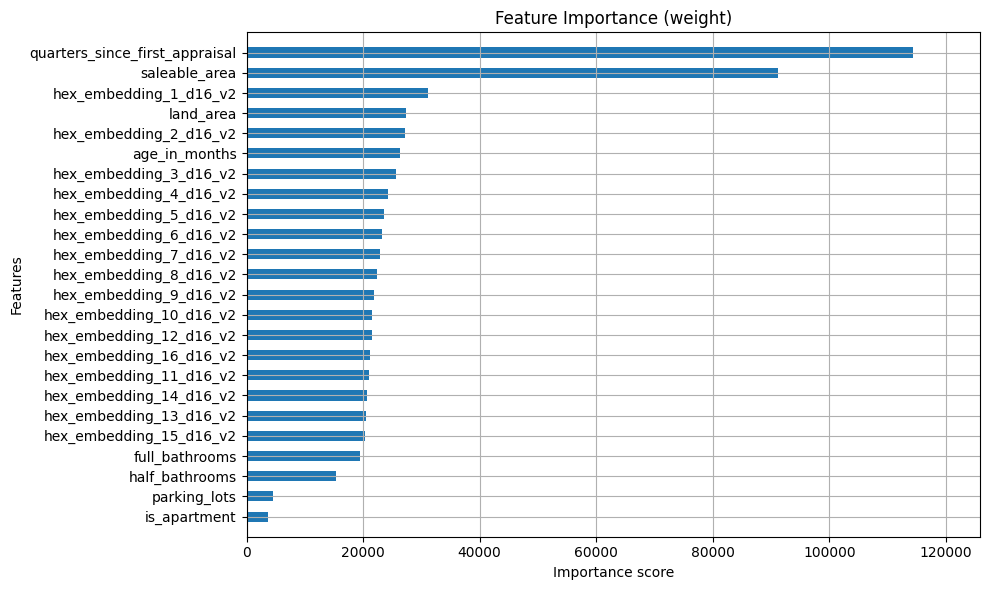

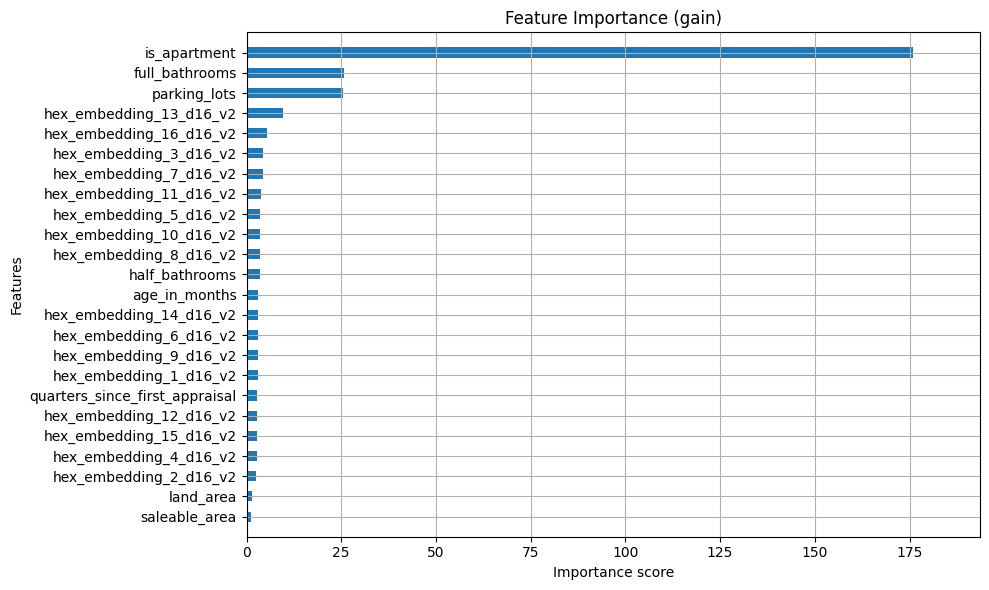

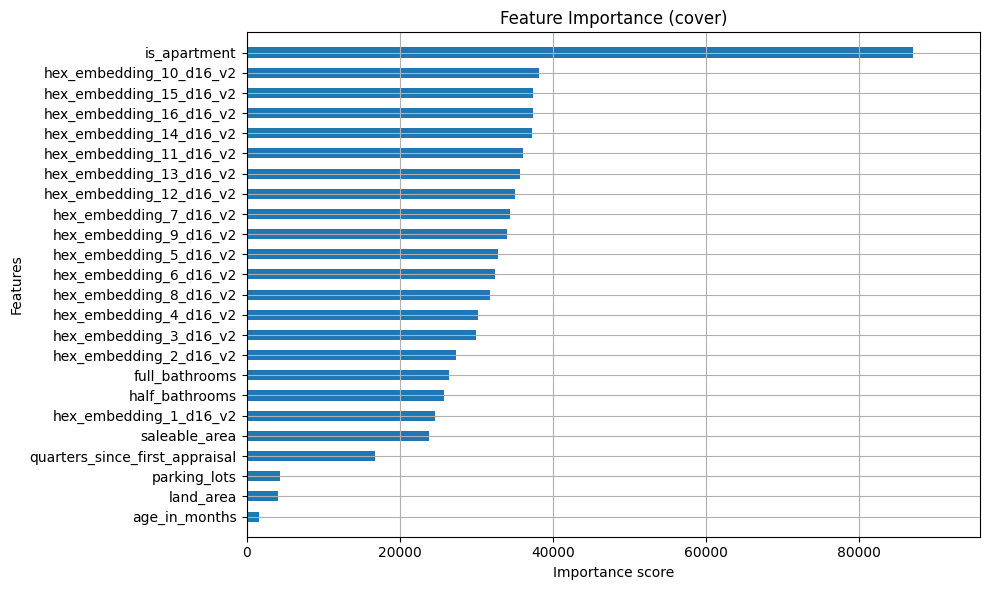

In [17]:
# model feature importance
for importance_type in ["weight", "gain", "cover"]:   
    fig, ax = plt.subplots(figsize=(10, 6))
    xgb.plot_importance(
        model,
        max_num_features=None,
        height=0.5,
        ax=ax,
        importance_type=importance_type,
        show_values=False,
    )
    ax.set_title(f"Feature Importance ({importance_type})")
    plt.tight_layout()
    plt.show()

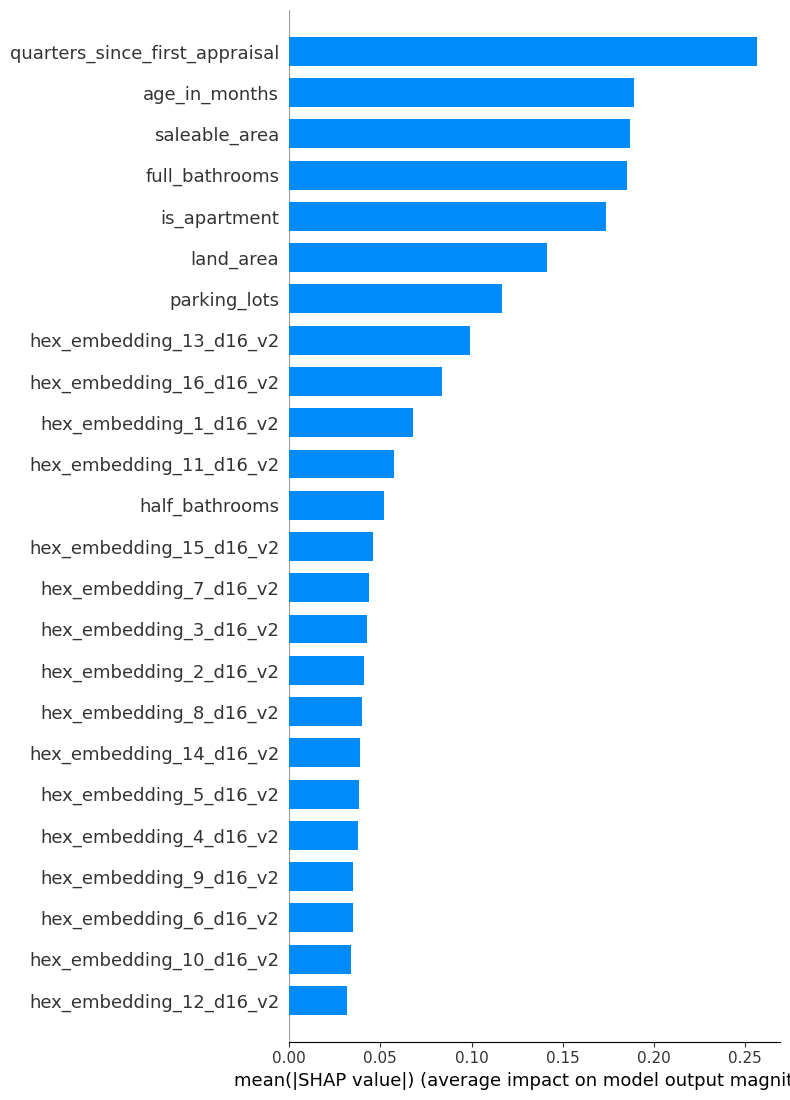

In [18]:
# plot feature importance according to shap values for non hex columns
shap.summary_plot(
    shap_values,
    X_sample,
    plot_type='bar',
    max_display=30
)

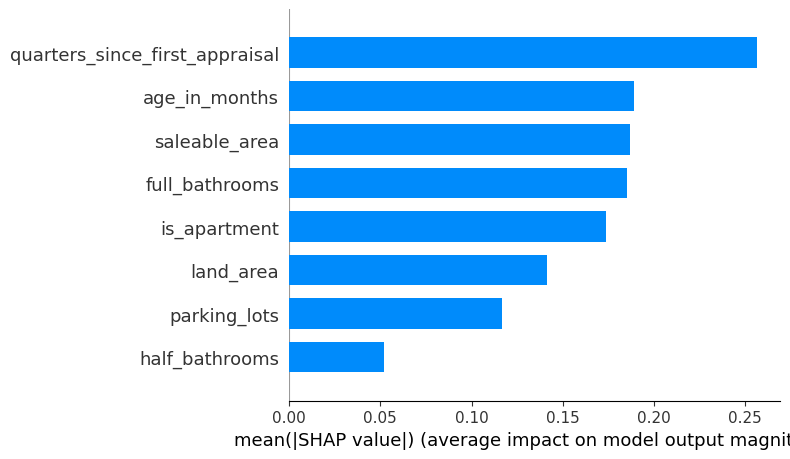

In [19]:
# plot feature importance according to shap values for non hex columns
shap.summary_plot(
    shap_values_non_hex,
    X_sample[non_hex_columns],
    plot_type='bar',
    max_display=20
)

## Cohorts

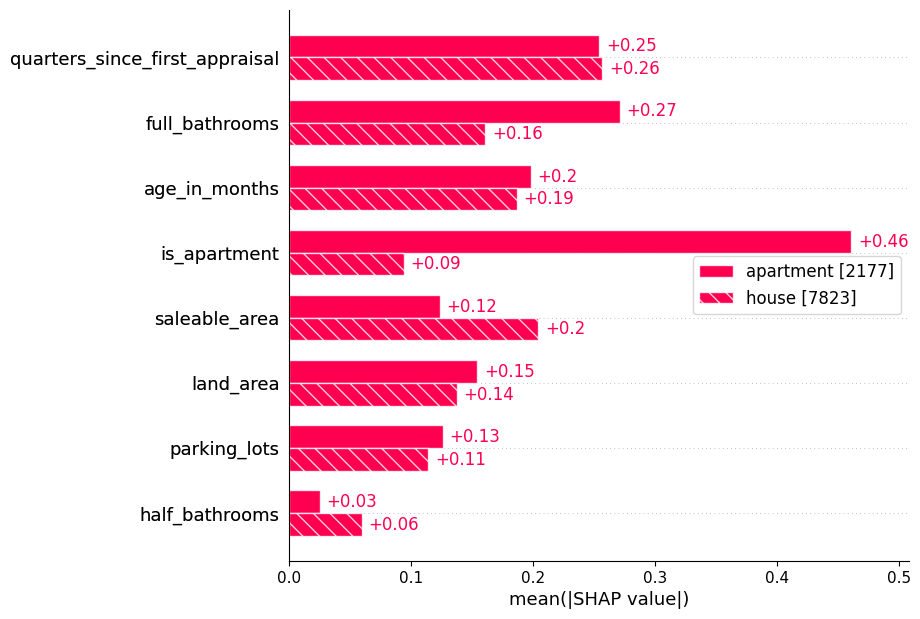

In [20]:
# mask list of type of property
property_mask_list = X_sample['is_apartment'].map({0: 'house', 1: 'apartment'}).to_list()

# plot importance per cohort
shap.plots.bar(
    shap_values_non_hex.cohorts(property_mask_list),
    max_display=20
)

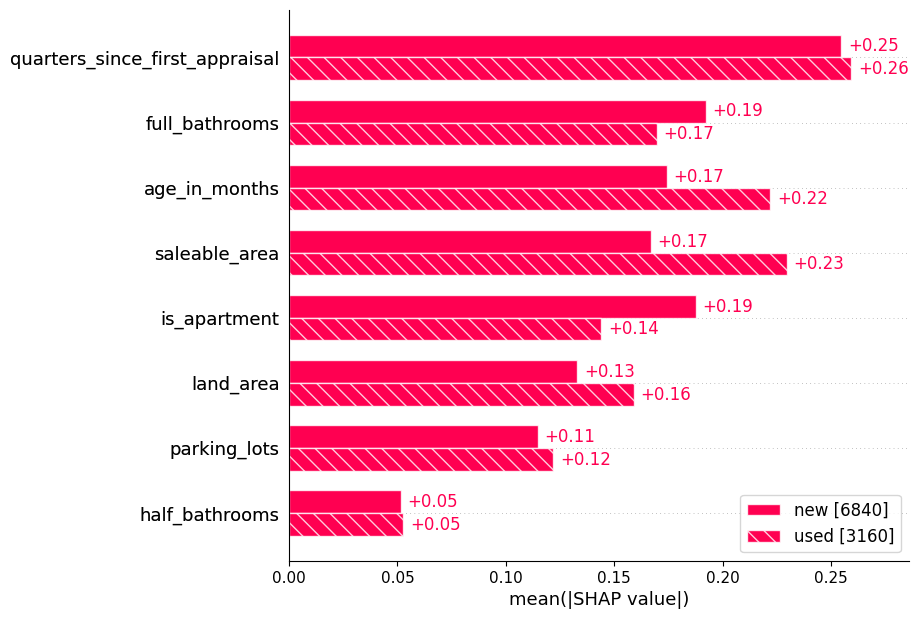

In [32]:
# mask list of new vs not new
new_mask_list = X_sample['age_in_months'].apply(lambda x: 'new' if x <= 5 * 12 else 'used').to_list()  # five years

# plot importance per cohort
shap.plots.bar(
    shap_values_non_hex.cohorts(new_mask_list),
    max_display=20
)

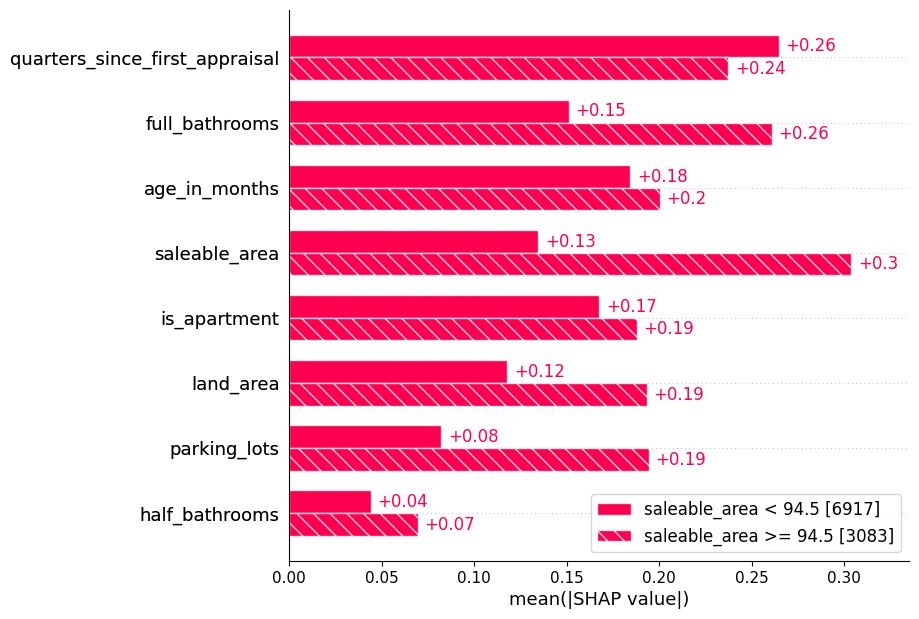

In [22]:
# cohort bar by optimally separated
shap.plots.bar(
    shap_values_non_hex.cohorts(2),
    max_display=20
    )

---
# Feature-Objective Direction

## Univariate

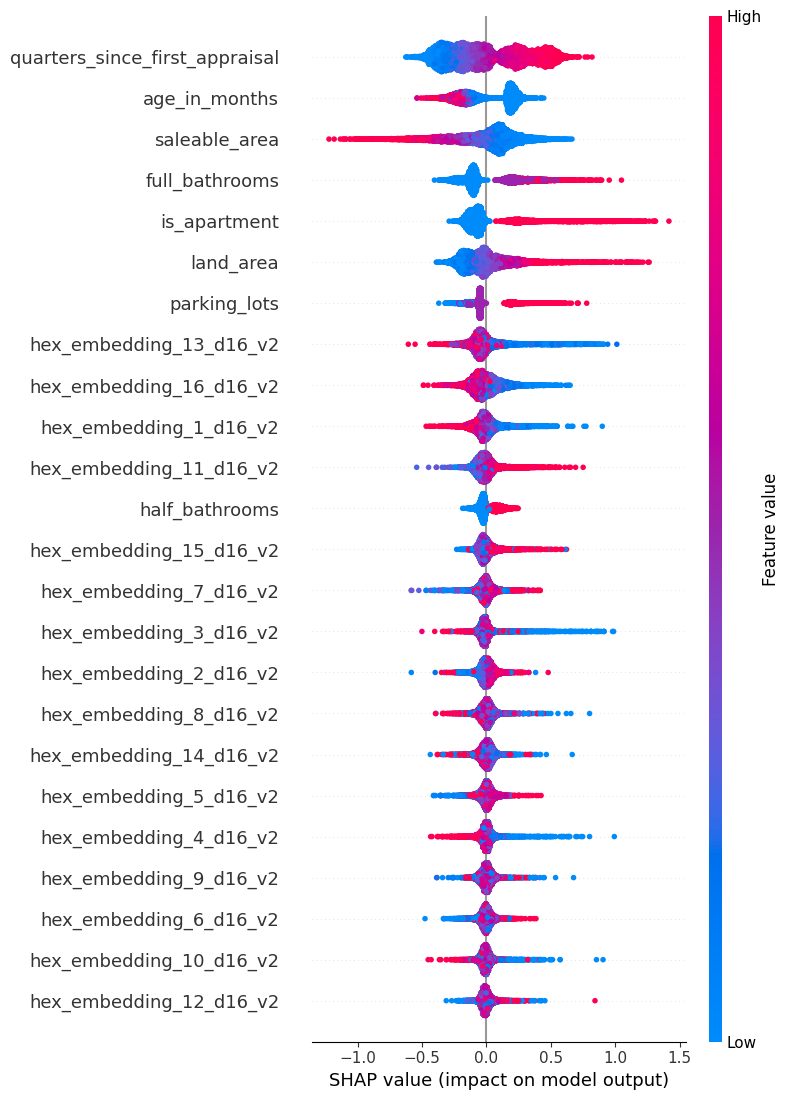

In [23]:
# summary plot
fig, ax = plt.subplots(figsize=(12, 8))
shap.summary_plot(
    shap_values,
    X_sample,
    max_display=30,
    show=False
)
plt.tight_layout()
plt.show()

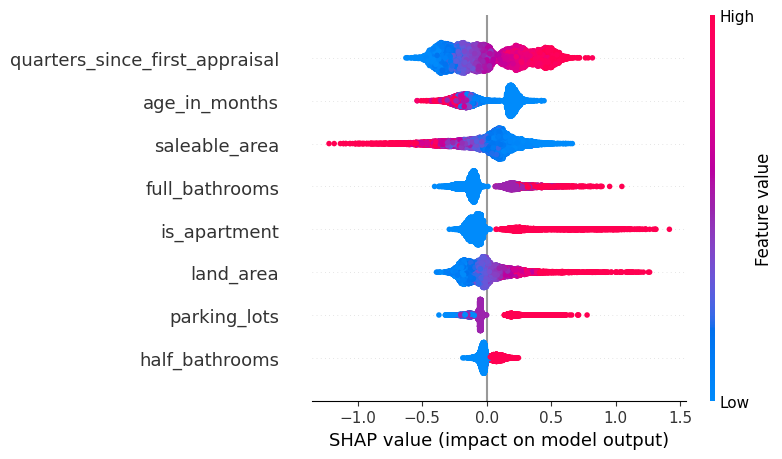

In [24]:
# summary plot non hex
fig, ax = plt.subplots(figsize=(12, 8))
shap.summary_plot(
    shap_values_non_hex,
    X_sample[non_hex_columns],
    max_display=20,
    show=False
)
plt.tight_layout()
plt.show()

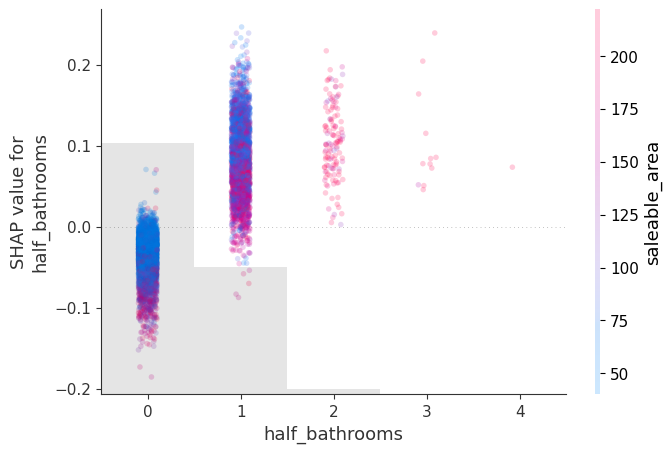

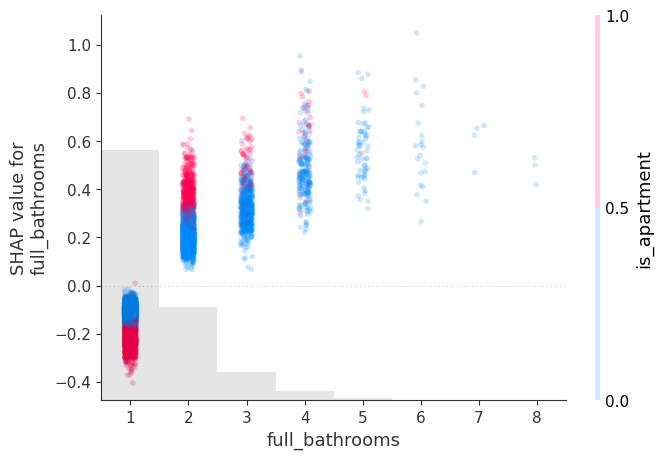

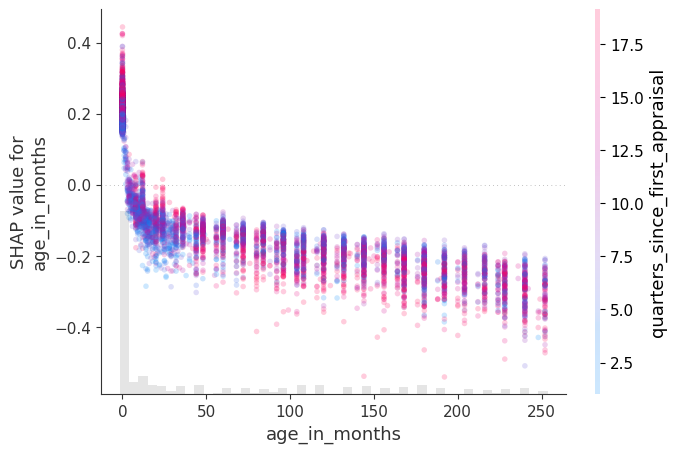

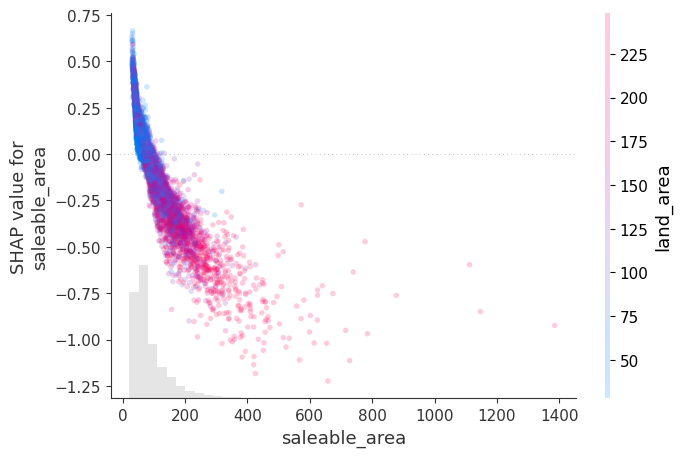

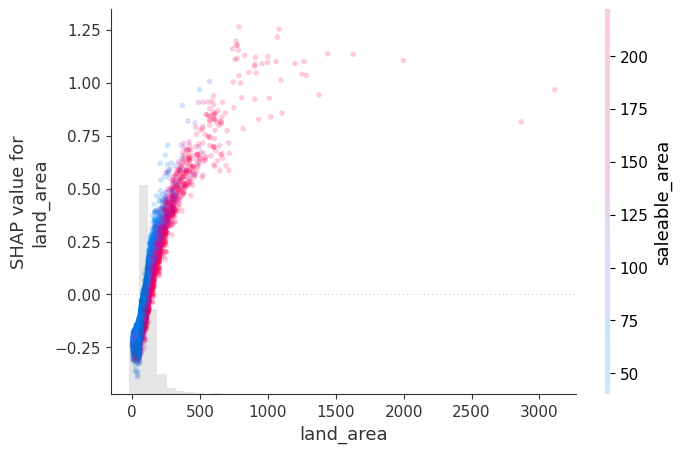

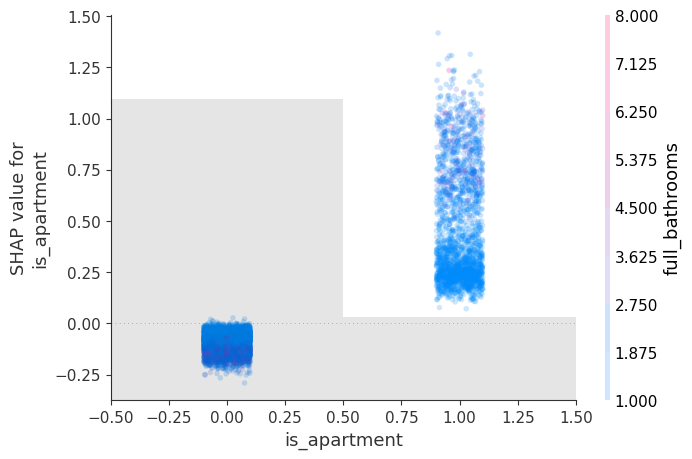

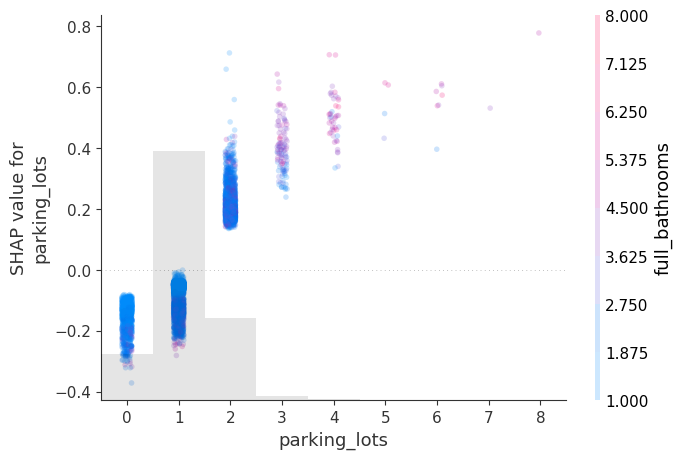

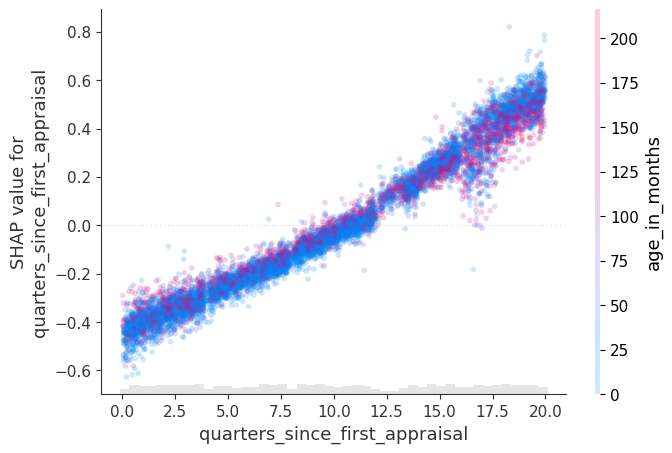

In [25]:
# for each feature, plot the scater plot of feature value vs shap value
for feature in non_hex_columns:
    shap.plots.scatter(
        shap_values_non_hex[:, feature],
        color=shap_values_non_hex,
        alpha=0.2,
        )

## Interactions

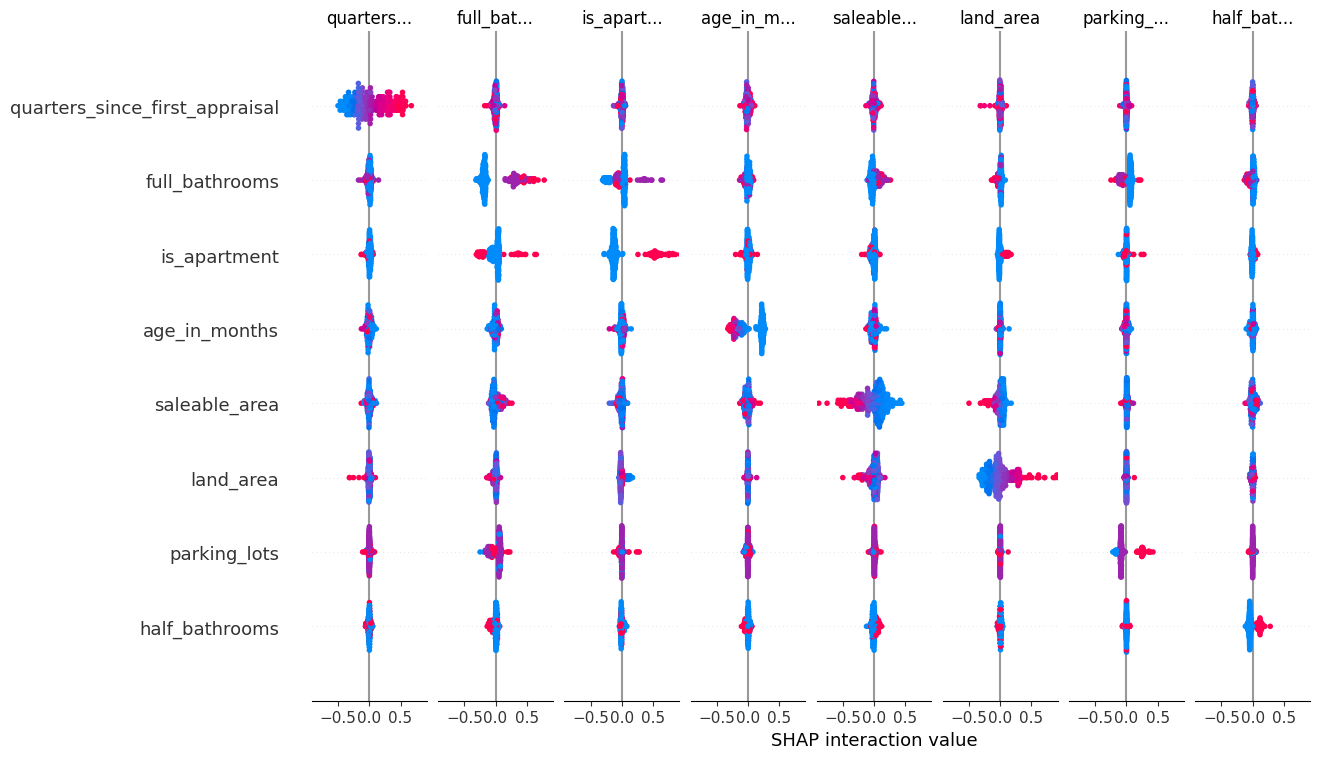

In [26]:
# plot interaction values for all features
shap.summary_plot(
    shap_interaction_values_non_hex,
    X_sample.iloc[:n_interactions][non_hex_columns],
    max_display=20
)

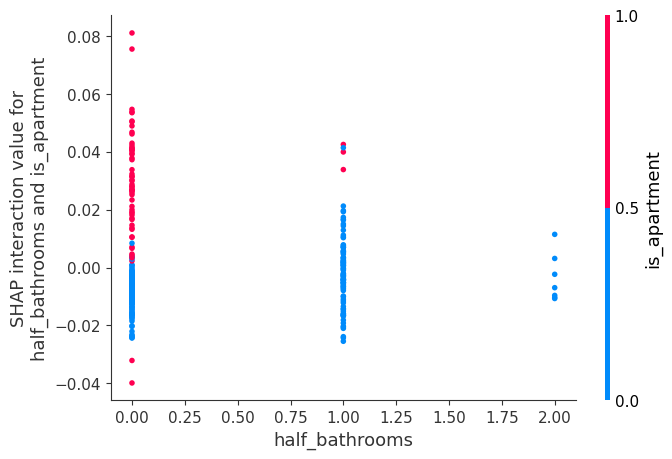

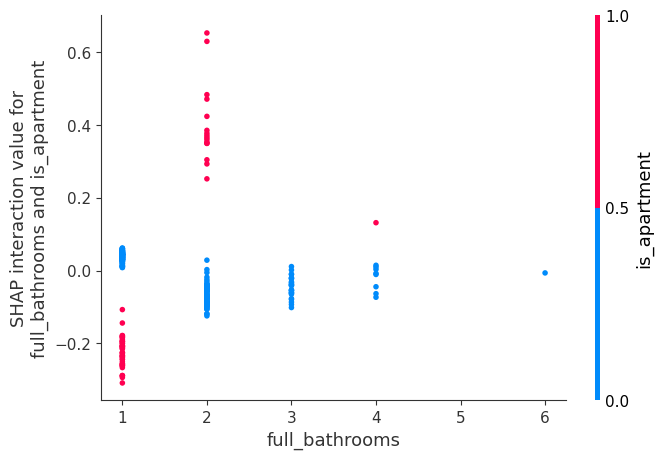

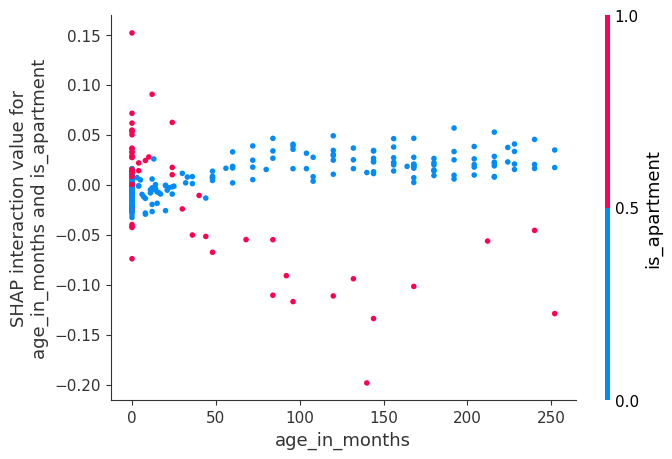

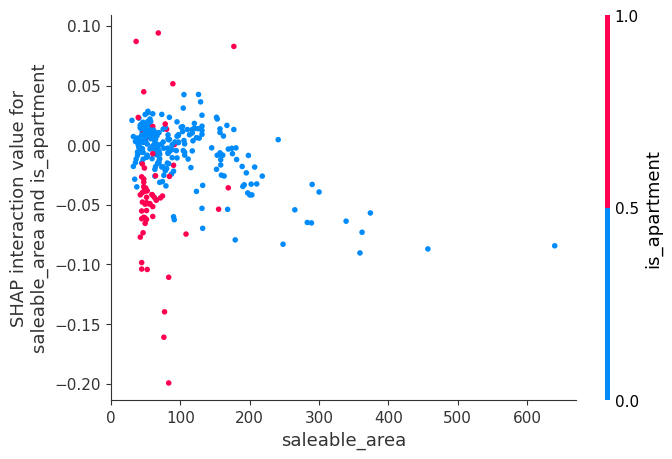

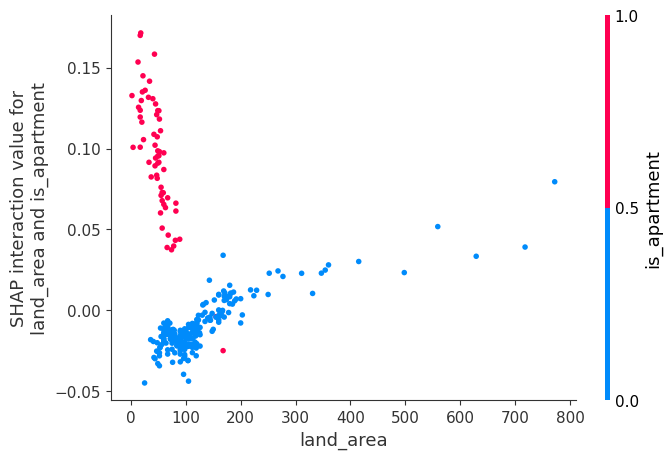

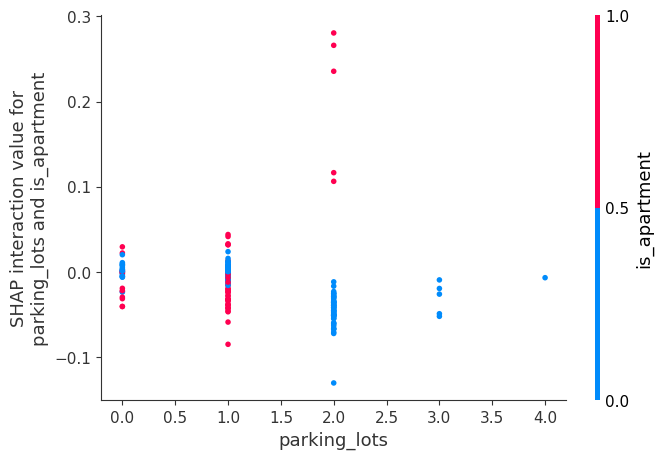

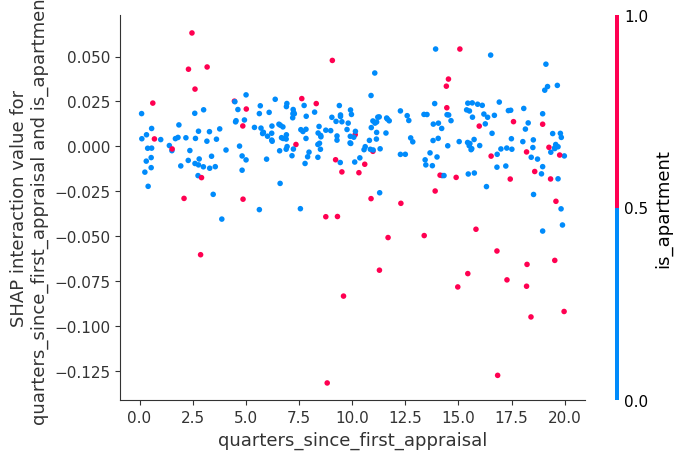

In [27]:
# interactions with is_apartment
for feature in non_hex_columns:
    if feature != 'is_apartment':
        shap.dependence_plot(
            (feature, 'is_apartment'),
            shap_interaction_values_non_hex,
            X_sample.iloc[:n_interactions][non_hex_columns],
            display_features=X_sample.iloc[:n_interactions][non_hex_columns],
            interaction_index='is_apartment'
        )

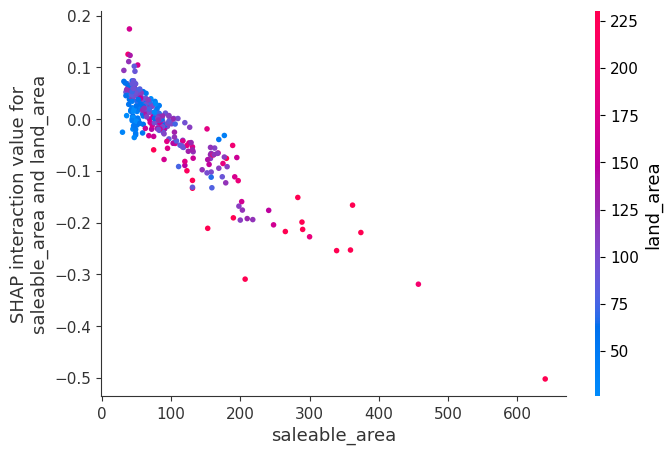

In [34]:
# interaction saleable_area and land_area
shap.dependence_plot(
    ('saleable_area', 'land_area'),
    shap_interaction_values,
    X_sample[:n_interactions],
    display_features=X_sample[:n_interactions],
    interaction_index='land_area'
)

## Correlations

In [35]:
# get df of shap values
df_shaps = pd.DataFrame(
    shap_values.values,
    columns=shap_values.feature_names,
    index=X_sample.index
)

# look
print(df_shaps.shape)
df_shaps.head()

(10000, 24)


,half_bathrooms,full_bathrooms,age_in_months,saleable_area,land_area,is_apartment,parking_lots,quarters_since_first_appraisal,hex_embedding_1_d16_v2,hex_embedding_2_d16_v2,hex_embedding_3_d16_v2,hex_embedding_4_d16_v2,hex_embedding_5_d16_v2,hex_embedding_6_d16_v2,hex_embedding_7_d16_v2,hex_embedding_8_d16_v2,hex_embedding_9_d16_v2,hex_embedding_10_d16_v2,hex_embedding_11_d16_v2,hex_embedding_12_d16_v2,hex_embedding_13_d16_v2,hex_embedding_14_d16_v2,hex_embedding_15_d16_v2,hex_embedding_16_d16_v2
observation_id,,,,,,,,,,,,,,,,,,,,,,,,
cf140687-c209-47e7-86a9-b8b0097da99f,0.042910,0.180509,0.199078,-0.251324,-0.031901,-0.137356,0.176210,-0.372530,-0.078535,-0.014620,-0.057750,-0.016494,0.000593,0.027357,0.015032,-0.049132,-0.015296,-0.016525,0.012556,-0.022781,0.083947,-0.036698,0.075592,0.023209
1fbf40ff-c211-48f4-a604-82309972cfae,-0.014933,-0.123246,0.192347,0.018344,0.310691,-0.006979,-0.044155,-0.193998,-0.016393,-0.036555,-0.024518,0.011899,0.022622,-0.033458,0.008014,-0.027651,-0.014310,-0.052352,0.012237,0.127365,-0.106981,-0.038481,-0.038134,-0.053309
2a98fcb7-48da-4f78-8c9c-4d2ab67537ba,0.080879,0.202346,-0.132820,-0.345403,-0.178079,-0.108043,-0.138630,0.207617,0.104361,0.023622,0.028777,0.039557,0.072461,-0.020542,0.040643,0.043068,0.067930,0.167667,-0.052325,0.025263,-0.007090,0.217180,0.066943,-0.044392
4c503a06-1636-41d9-9338-1ebbeea7e29d,-0.046102,-0.109989,0.225477,0.144472,-0.057702,-0.066786,-0.052377,0.589961,0.149031,0.067866,0.028601,0.058344,0.037977,-0.074735,0.051558,0.032738,-0.046162,0.008660,0.077120,0.019057,-0.091686,0.055436,0.016247,-0.119128
4b923e59-8617-49ae-a273-f3679b82afbe,-0.018217,-0.184341,0.424849,0.407051,-0.215557,0.655615,-0.132370,0.337642,0.772980,0.122903,0.258971,0.001833,0.035608,0.054472,0.009223,0.176523,0.044968,0.093552,0.002273,0.000028,0.008328,0.060247,0.108149,0.042275


<Figure size 1200x1000 with 0 Axes>

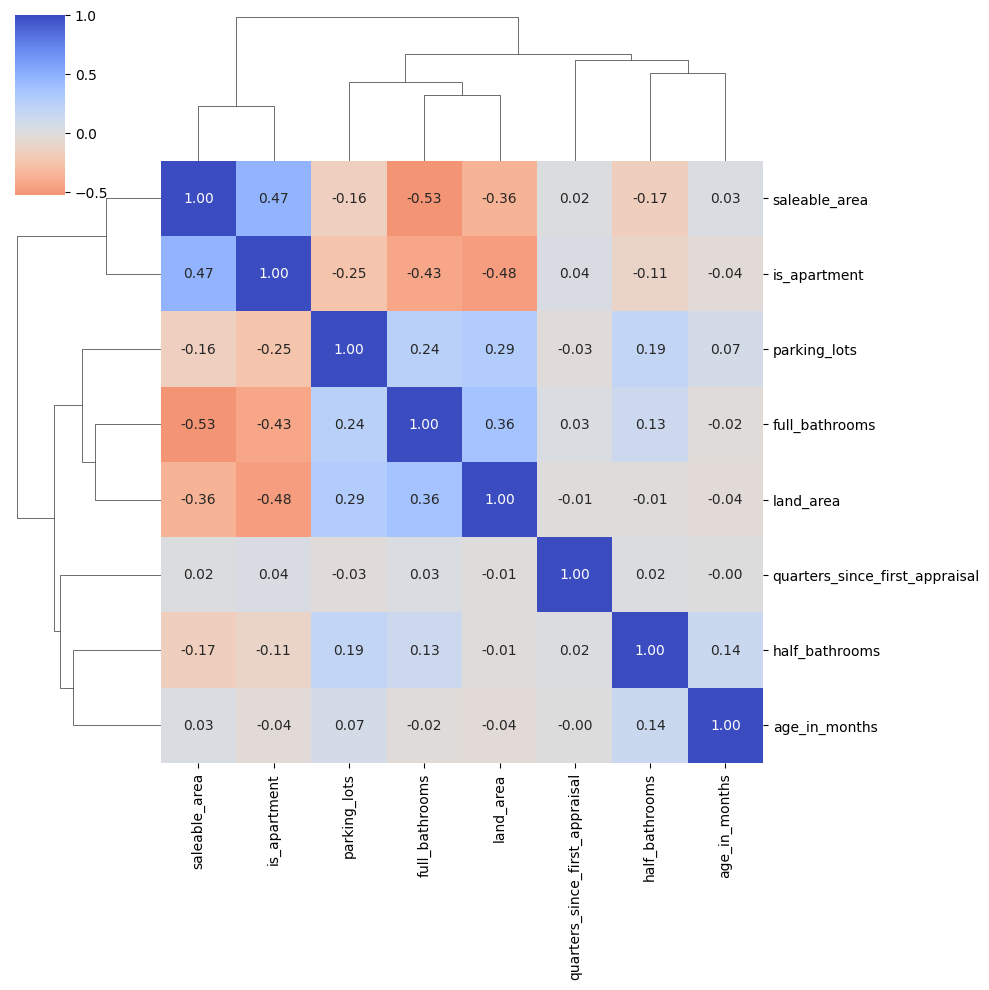

In [38]:
# normal correlation matrix
plt.figure(figsize=(12, 10))
sns.clustermap(
    df_shaps[non_hex_columns].corr(method='spearman'),
    annot=True,
    fmt=".2f",
    cmap='coolwarm_r',
    center=0,
    cbar_kws={'shrink': 0.8}
)

<Figure size 1200x1000 with 0 Axes>

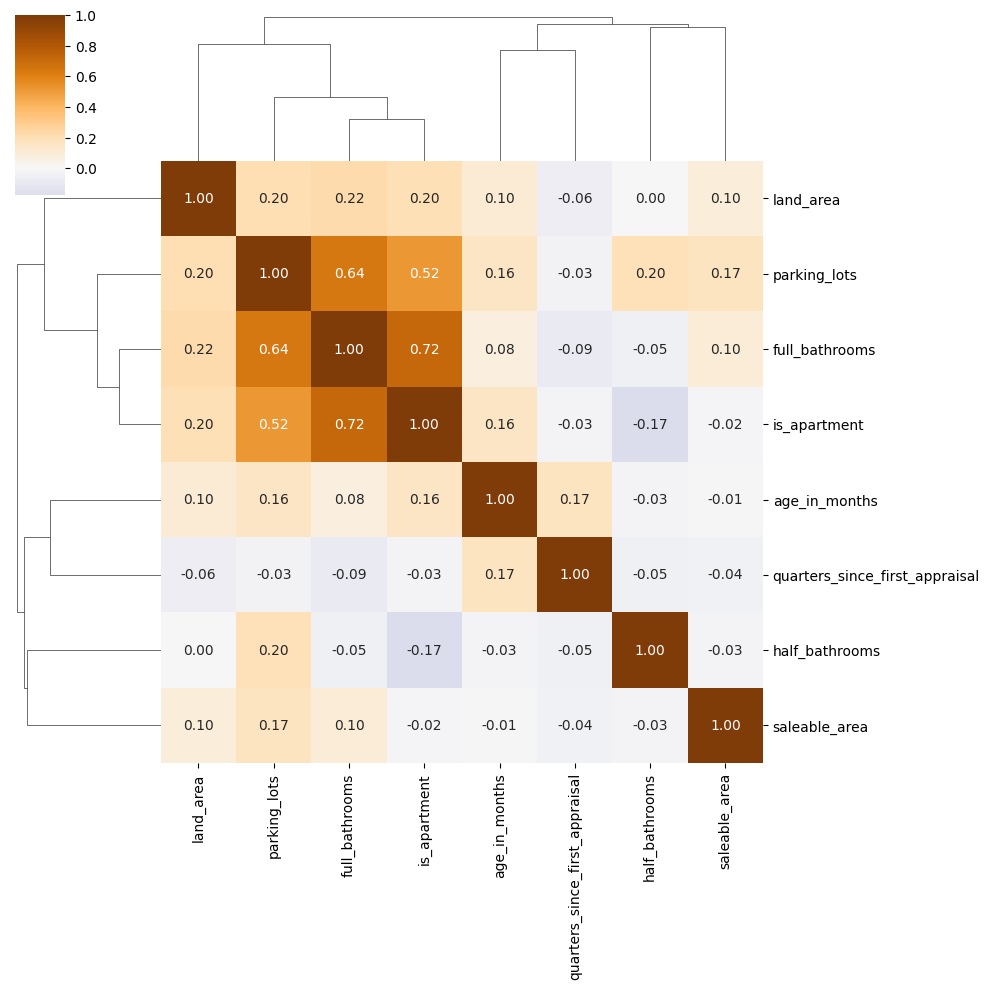

In [37]:
# abs correlation matrix
plt.figure(figsize=(12, 10))
sns.clustermap(
    df_shaps[non_hex_columns].abs().corr(method='spearman'),
    annot=True,
    fmt=".2f",
    cmap='PuOr_r',
    center=0,
    cbar_kws={'shrink': 0.8}
)

---
# Prototypes

## Heatmaps

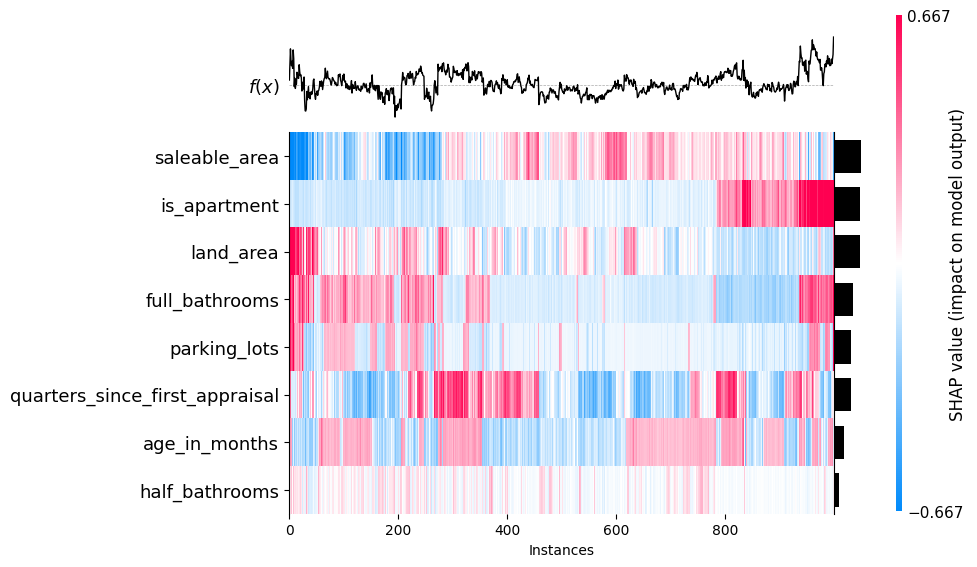

<Axes: xlabel='Instances'>

In [40]:
# heat map of shap values (not hex columns)
shap.plots.heatmap(
    shap_values_non_hex[:1000],
    feature_values=shap_values_non_hex[:1000].abs.max(0)
    )

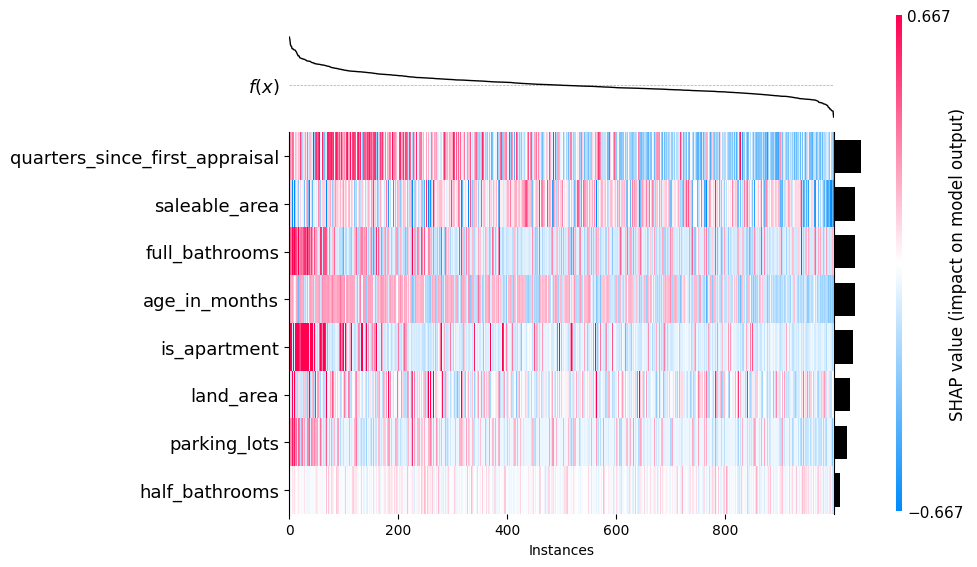

<Axes: xlabel='Instances'>

In [46]:
# heat map of shap values (not hex columns) but with total amount of importance ordering of observations
shap.plots.heatmap(
    shap_values_non_hex[:1000],
    instance_order=shap_values_non_hex[:1000].sum(1)
)

## Counterfactual (apartment)

### Seek

In [18]:
# Get prototype apartments
# fixed params
canonical_params = {
    # new property
    'age_in_months': 0,
}

# apartment near condesa
for c in gdf_hex_embeddings.filter(like='hex_embedding').columns:
    canonical_params[c] = gdf_hex_embeddings.query("hex_id == '894995ba39bffff'")[c].values[0]

# get apartments from the sample
X_apartments = X_sample.query("is_apartment == 1").copy()

# fix canonical params
for k, v in canonical_params.items():
    X_apartments[k] = v

# describe
X_apartments.describe().T[['mean', 'std']].sort_values('std', ascending=False).query("std > 0")

,mean,std
saleable_area,67.216812,38.884442
land_area,51.435002,33.672631
quarters_since_first_appraisal,10.682353,5.862130
full_bathrooms,1.350482,0.634335
parking_lots,0.938447,0.630765
half_bathrooms,0.067065,0.260980


In [33]:
# Get shap values of the prototypes
# get shaps
dmat = xgb.DMatrix(X_apartments, feature_names=model_feature_names)
contrib = model.predict(dmat, pred_contribs=True)  # another way to get shap values

# subset important columns
shap_matrix = contrib[:, :-1]      # [n, p] per-feature contributions
bias_vector = contrib[:, -1]       # [n] expected_value per row
preds = bias_vector + shap_matrix.sum(axis=1)

In [34]:
# Find prototype by nearest to mean shap values
centroid = shap_matrix.mean(axis=0)
diffs = shap_matrix - centroid
dists = np.sqrt((diffs * diffs).sum(axis=1))
rep_idx = int(np.argmin(dists))

# look
X_apartments.iloc[rep_idx]

half_bathrooms                     0.000000
full_bathrooms                     1.000000
age_in_months                      0.000000
saleable_area                     67.000000
land_area                         28.000000
is_apartment                       1.000000
parking_lots                       1.000000
quarters_since_first_appraisal    10.438596
hex_embedding_1_d16_v2             0.431450
hex_embedding_2_d16_v2            -0.712101
hex_embedding_3_d16_v2            -2.195735
hex_embedding_4_d16_v2            -2.417367
hex_embedding_5_d16_v2             1.011254
hex_embedding_6_d16_v2            -0.622554
hex_embedding_7_d16_v2             1.460052
hex_embedding_8_d16_v2             0.720485
hex_embedding_9_d16_v2            -0.668630
hex_embedding_10_d16_v2           -1.823348
hex_embedding_11_d16_v2           -0.107965
hex_embedding_12_d16_v2            0.841126
hex_embedding_13_d16_v2           -3.047433
hex_embedding_14_d16_v2            1.031746
hex_embedding_15_d16_v2         

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 2177 samples in 0.000s...
[t-SNE] Computed neighbors for 2177 samples in 0.345s...
[t-SNE] Computed conditional probabilities for sample 1000 / 2177
[t-SNE] Computed conditional probabilities for sample 2000 / 2177
[t-SNE] Computed conditional probabilities for sample 2177 / 2177
[t-SNE] Mean sigma: 0.059256
[t-SNE] KL divergence after 250 iterations with early exaggeration: 56.848740
[t-SNE] KL divergence after 1000 iterations: 0.468140


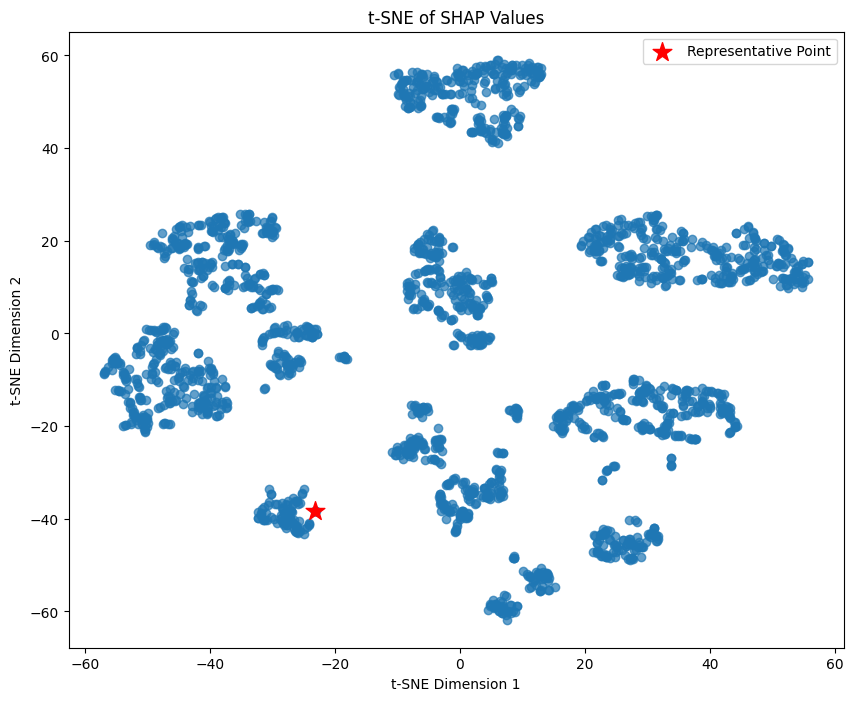

In [35]:
# visualize the SHAP values for that representative observation using TSNE
tsne = TSNE(n_components=2, random_state=42, perplexity=30, verbose=1)
Z = tsne.fit_transform(shap_matrix)  # [n, 2] embedding of SHAP values

# plot
fig, ax = plt.subplots(figsize=(10, 8))

# plot all
scatter = ax.scatter(
    Z[:, 0], Z[:, 1],
    alpha=0.7
    )

# plot representative point
ax.scatter(
    Z[rep_idx, 0], Z[rep_idx, 1],
    color='red', s=200, marker='*',
    label='Representative Point'
    )

# decorate
ax.set_title('t-SNE of SHAP Values')
ax.set_xlabel('t-SNE Dimension 1')
ax.set_ylabel('t-SNE Dimension 2')
ax.legend()
plt.show()

### Explore

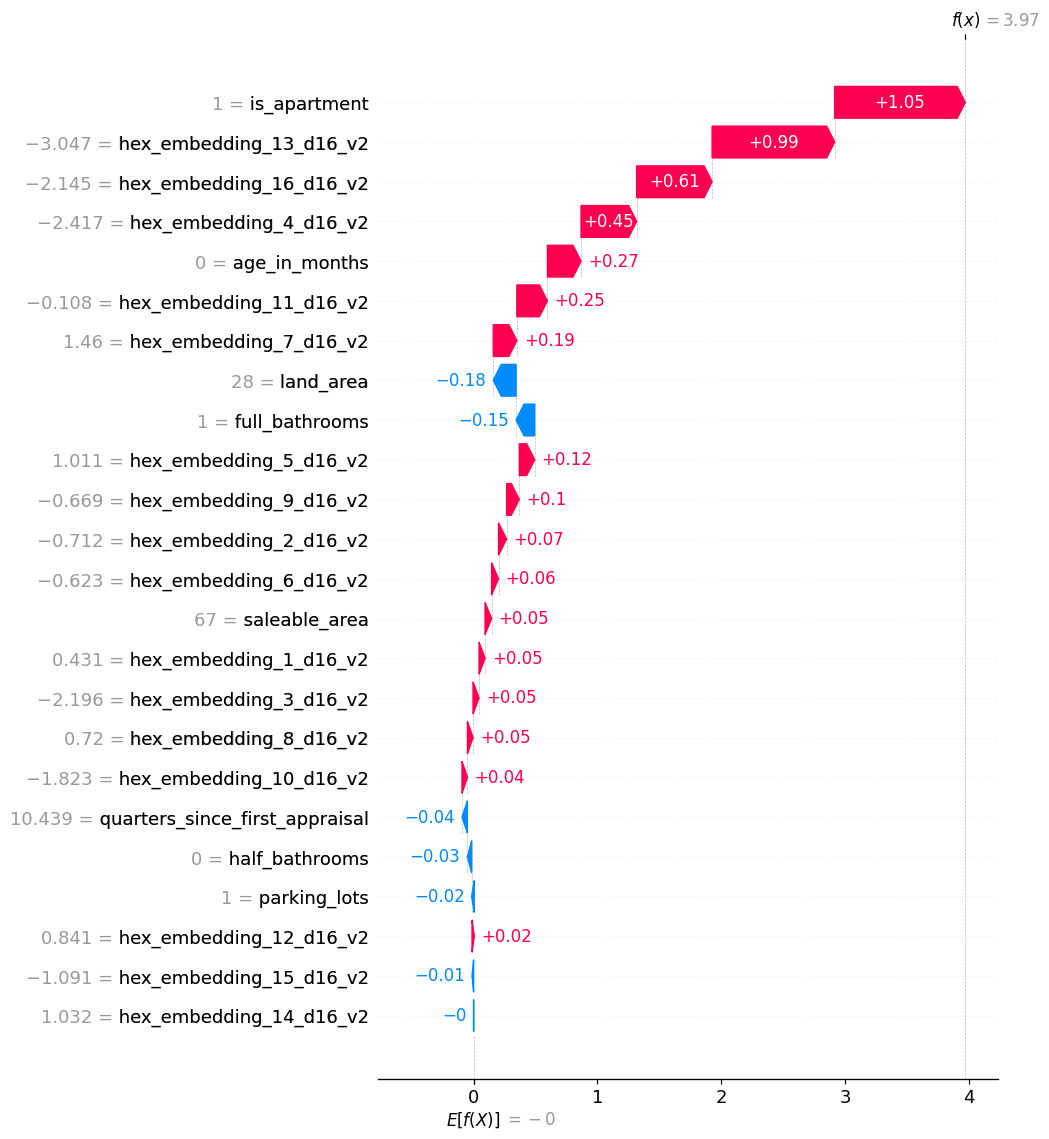

In [36]:
# waterfall plot of representative point
shap.plots.waterfall(
    shap.Explanation(
        values=shap_matrix[rep_idx],
        base_values=bias_vector[rep_idx],
        data=X_apartments.iloc[rep_idx],
        feature_names=model_feature_names
    ),
    max_display=25
)

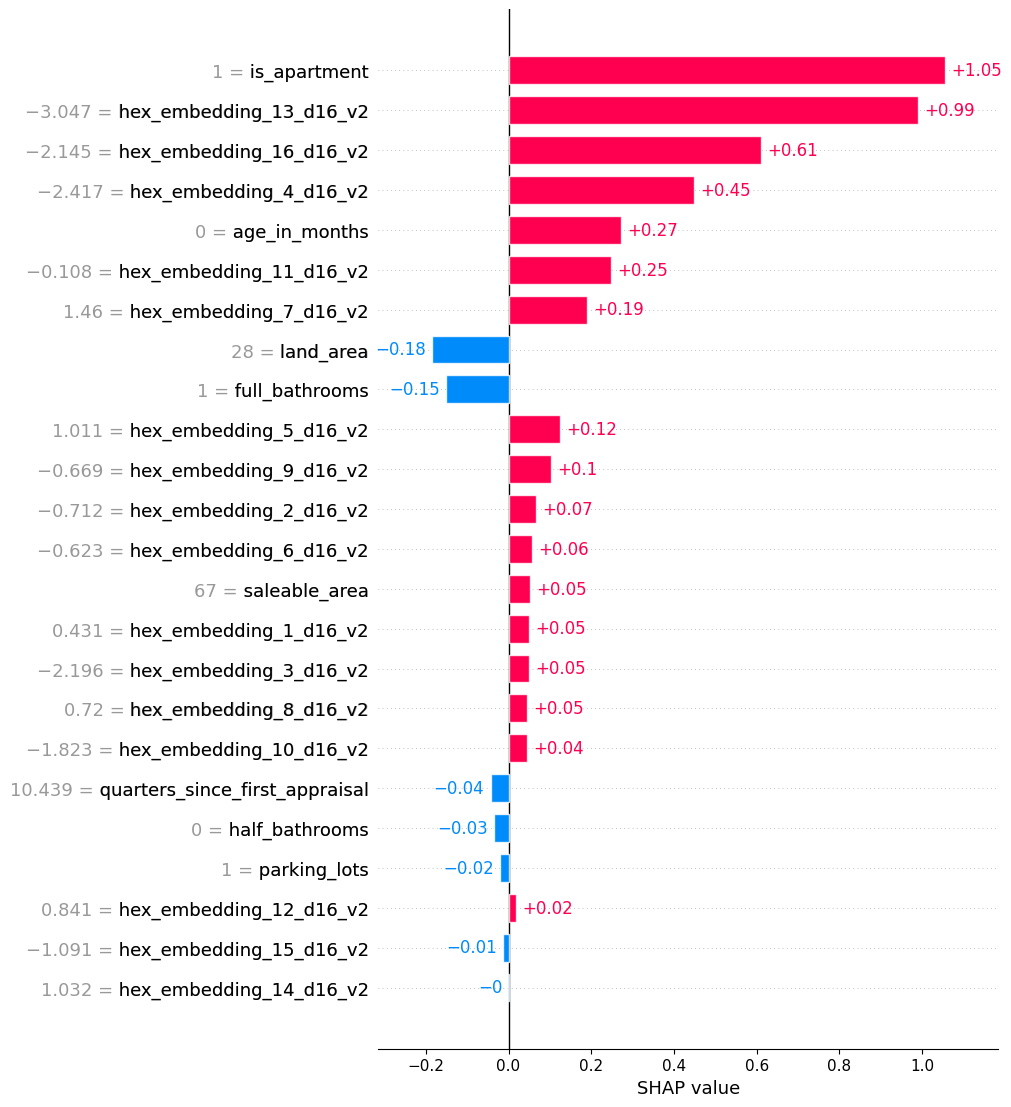

In [37]:
# waterfall but with bar
shap.plots.bar(
    shap.Explanation(
        values=shap_matrix[rep_idx],
        base_values=bias_vector[rep_idx],
        data=X_apartments.iloc[rep_idx],
        feature_names=model_feature_names
    ),
    max_display=25
)

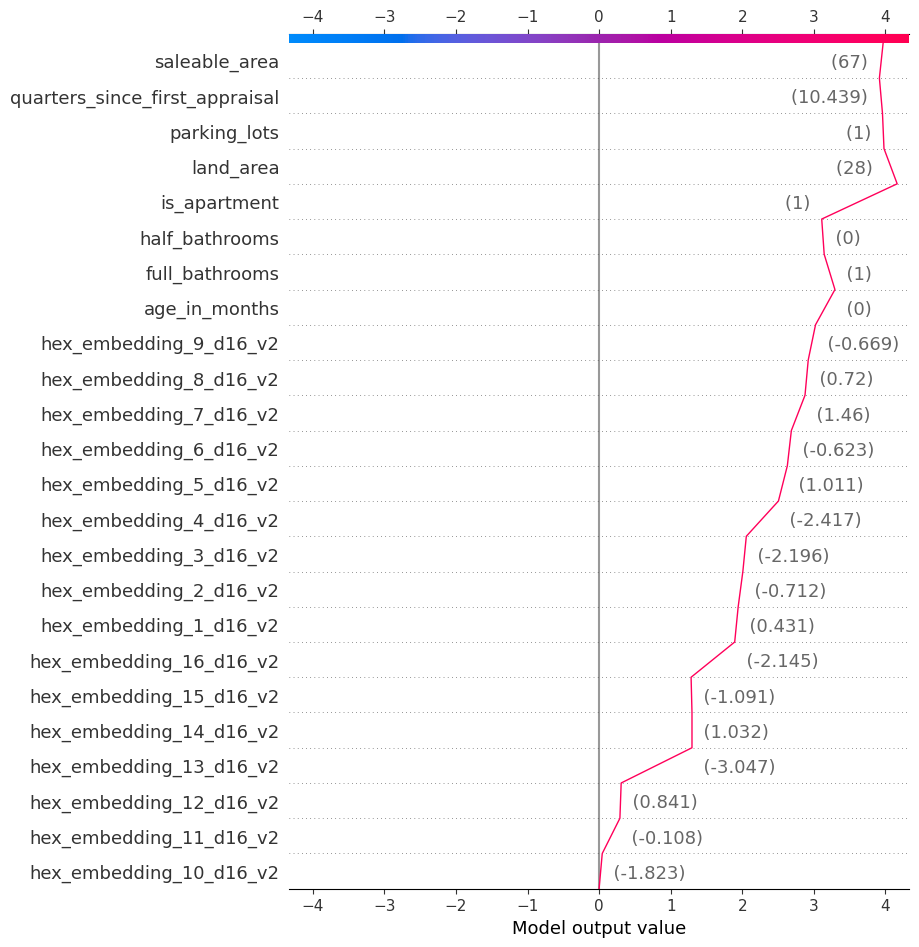

In [38]:
# path plot
shap.decision_plot(
    base_value=bias_vector[rep_idx],
    shap_values=shap_matrix[rep_idx],
    features=X_apartments.iloc[rep_idx],
    feature_order=feature_order_sorted_indexes,
    feature_display_range=slice(None, None, -1)
)

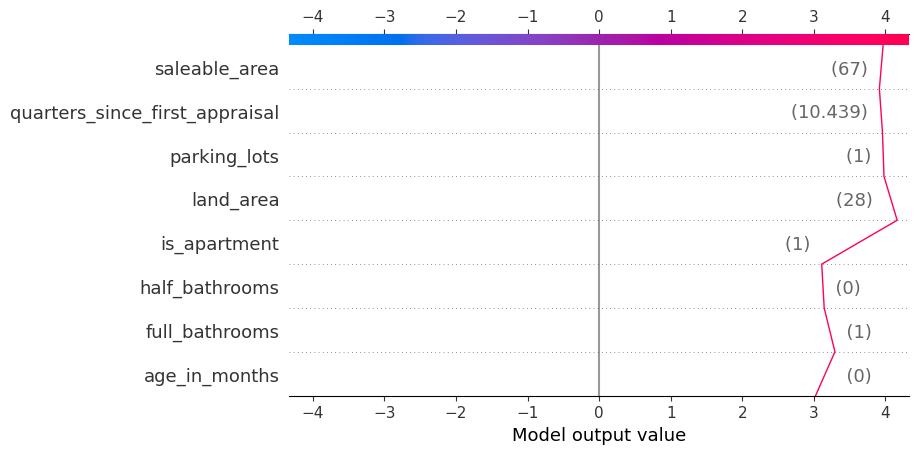

In [39]:
# path without hex
num_non_hex = len(non_hex_columns)

shap.decision_plot(
    base_value=bias_vector[rep_idx],
    shap_values=shap_matrix[rep_idx],
    features=X_apartments.iloc[rep_idx],
    feature_order=feature_order_sorted_indexes,
    feature_display_range=slice(None, -num_non_hex - 1, -1)
)

## Typical Paths 

### Same PPSM at same place

In [40]:
# get properties in a neighborhood that have +/- 10% the value of the representative
repr_idx = X_sample.index[rep_idx]

# get predicted value of representative
repr_value = get_target_value(preds[[rep_idx]], transformer)[0]
print(f"Representative predicted value: ${repr_value:,.0f} mxn")

Representative predicted value: $76,174 mxn


In [41]:
# get properties in the same hex
X_prototypes = X.copy()

# join with original properties (only neighborhood and price)
X_prototypes = X_prototypes.join(
    df_properties[['neighborhood', 'y']],
    how='inner'
)

# mask
# places
neighborhood_list = [
    'ROMA', 'ROMA SUR', 'ROMA NORTE', 'CONDESA', 'HIPODROMO CONDESA'
]
mask = (
    (X_prototypes['neighborhood'].isin(neighborhood_list)) & # same neighborhood
    (X_prototypes.index != repr_idx) & # not the same property
    (X_prototypes['is_apartment'].eq(1)) &  # must be an apartment
    (X_prototypes['y'].between(repr_value * 0.9, repr_value * 1.1)) # +/- 10%
)
X_prototypes = X_prototypes[mask]
print(f"Properties in zone: {X_prototypes.shape[0]}")
X_prototypes

Properties in zone: 272


,half_bathrooms,full_bathrooms,age_in_months,saleable_area,land_area,is_apartment,parking_lots,quarters_since_first_appraisal,hex_embedding_1_d16_v2,hex_embedding_2_d16_v2,hex_embedding_3_d16_v2,hex_embedding_4_d16_v2,hex_embedding_5_d16_v2,hex_embedding_6_d16_v2,hex_embedding_7_d16_v2,hex_embedding_8_d16_v2,hex_embedding_9_d16_v2,hex_embedding_10_d16_v2,hex_embedding_11_d16_v2,hex_embedding_12_d16_v2,hex_embedding_13_d16_v2,hex_embedding_14_d16_v2,hex_embedding_15_d16_v2,hex_embedding_16_d16_v2,neighborhood,y
observation_id,,,,,,,,,,,,,,,,,,,,,,,,,,
bf9fa949-eb73-43db-949b-a13aa003f281,1,4,0,112,59,1,2,8.530702,0.832527,-1.047166,-2.347585,-2.138693,1.245901,-0.745774,1.722652,0.568473,-0.710347,-1.276902,0.097608,1.009829,-3.142998,0.845310,-0.713916,-2.131737,ROMA SUR,79276.785714
1a81e8a2-1732-493c-9fd4-2295e7d64483,0,1,56,40,24,1,0,10.548246,0.281654,-0.448239,-2.135570,-2.442408,1.003862,-0.562115,1.171684,1.072882,-0.624375,-1.975862,-0.338230,0.550342,-2.844877,0.966257,-1.345183,-2.222687,CONDESA,83100.000000
4d7fa7f0-ea90-4111-a977-b7594bca2830,1,2,0,99,16,1,2,11.140351,0.705943,-1.001266,-2.264259,-2.148513,1.107386,-0.822328,1.736835,0.348536,-0.598391,-1.364736,-0.013472,1.093289,-3.250978,1.041112,-0.579679,-2.109419,ROMA SUR,78888.888889
0701a7e5-69c4-4cb6-a1b9-f07008135905,0,3,0,144,57,1,3,2.094298,0.219702,-0.356497,-2.009627,-2.532627,0.979764,-0.600207,1.255992,0.911447,-0.691275,-2.044333,-0.217527,0.749184,-2.983283,1.210064,-1.262939,-2.082719,ROMA NORTE,69319.444444
3b6bf804-0fb2-499c-856e-46e4affd1d96,0,3,0,94,24,1,2,19.188596,-0.103440,-0.631284,-1.631981,-2.285964,0.416447,-0.662356,1.580682,-0.173357,-0.749458,-2.050279,-0.203160,1.298857,-3.427904,1.726107,-0.535921,-1.405670,ROMA NORTE,79148.936170
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
b34a5249-64f1-4683-bef5-e0442e06dd4b,0,2,12,84,84,1,2,17.357456,0.545777,-0.852216,-2.176073,-2.247830,0.967563,-0.676349,1.534830,0.429214,-0.683607,-1.544662,0.044732,1.049278,-3.195605,1.161076,-0.721395,-2.093566,ROMA NORTE,80119.047619
b53b2fae-bdf3-4748-a481-839cf6f67328,1,2,0,80,17,1,1,19.627193,0.386500,-0.672732,-2.031374,-2.463533,0.741883,-0.702451,1.605097,0.239720,-0.731554,-1.828912,-0.110542,1.164676,-3.281583,1.297435,-0.640786,-1.788266,ROMA NORTE,79887.500000
7cb6624d-4826-4895-b37f-0ea2445339f1,0,1,12,41,8,1,1,19.583333,0.318642,-0.801425,-2.014703,-2.346726,0.744971,-0.714240,1.695544,0.052021,-0.729644,-1.630749,-0.006653,1.250820,-3.267403,1.368162,-0.564903,-1.739782,ROMA NORTE,81682.926829


In [42]:
# get prototypes shap values
shap_values_prototypes = explainer.shap_values(X_prototypes[model_feature_names])
expected_value = explainer.expected_value

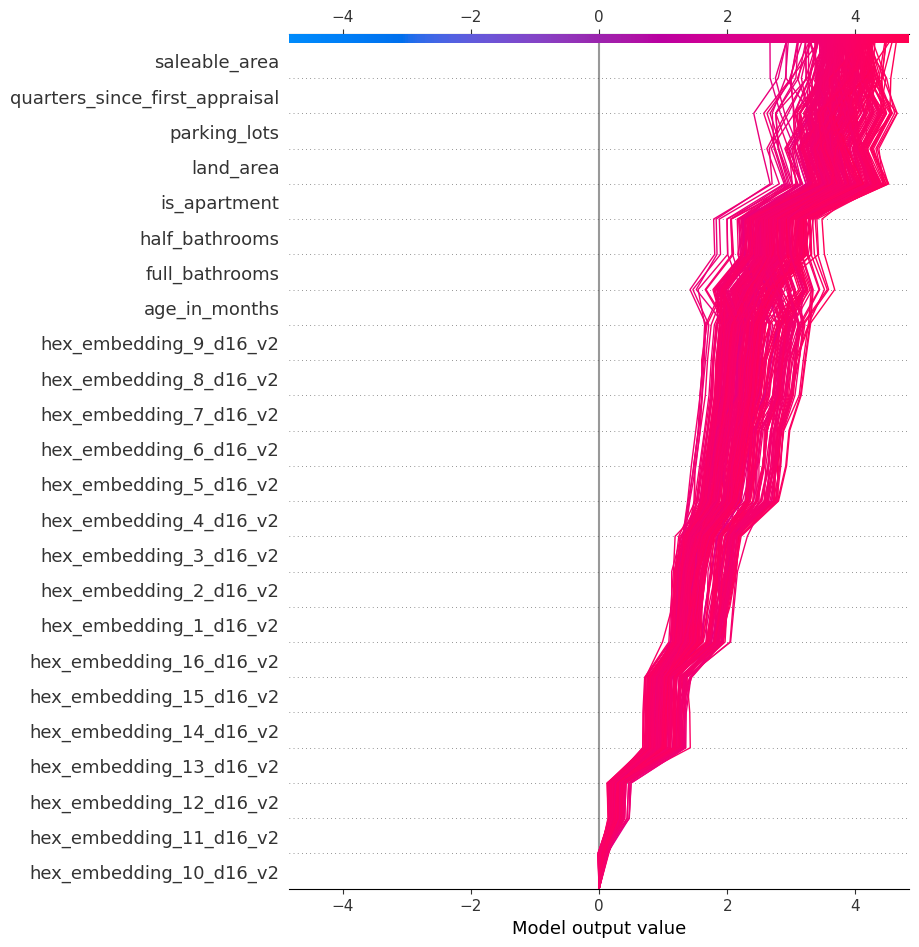

In [43]:
# plot paths for each property
shap.decision_plot(
    base_value=expected_value,
    shap_values=shap_values_prototypes,
    features=X_prototypes[model_feature_names],
    feature_names=model_feature_names,
    feature_order=feature_order_sorted_indexes,
    feature_display_range=slice(None, None, -1)
)

### Local Regions

In [44]:
# get disc of the following hexes
df_hexes_cdmx_repr = pd.DataFrame({
    'hex_id': [
        '894995ba39bffff', # roma
        '894995baebbffff', # polanco
        '894995b3387ffff', # santa fe
        '89499584ddbffff', # pedregal
        '894995ba47bffff', # del valle
    ],
    'neighborhood': [
        'ROMA',
        'POLANCO',
        'SANTA FE',
        'PEDREGAL',
        'DEL VALLE',
    ]
}).set_index('neighborhood')

# get 2 krings for each hex
gdf_hexes_cdmx_repr = (
    df_hexes_cdmx_repr
    .loc[:, 'hex_id']
    .apply(lambda x: pd.Series(list(h3.k_ring(x, 2))))
    .stack()
    .to_frame('hex_id')
    .reset_index(1, drop=True)
    .reset_index()
)

# merge with embeddings
gdf_hexes_cdmx_repr = (
    gdf_hexes_cdmx_repr
    .merge(
        gdf_hex_embeddings,
        on='hex_id',
        how='left'
    )
)

# get geometry
gdf_hexes_cdmx_repr = (
    gdf_hexes_cdmx_repr
    .assign(
        geometry=lambda x: x['hex_id'].apply(lambda h: Polygon(h3.h3_to_geo_boundary(h, geo_json=True)))
    )
    .set_geometry('geometry')
    .set_crs(epsg=4326)
    .to_crs(epsg=6372)
)

# look
print(gdf_hexes_cdmx_repr.shape)
gdf_hexes_cdmx_repr.head()


(95, 19)


,neighborhood,hex_id,hex_embedding_1_d16_v2,hex_embedding_2_d16_v2,hex_embedding_3_d16_v2,hex_embedding_4_d16_v2,hex_embedding_5_d16_v2,hex_embedding_6_d16_v2,hex_embedding_7_d16_v2,hex_embedding_8_d16_v2,hex_embedding_9_d16_v2,hex_embedding_10_d16_v2,hex_embedding_11_d16_v2,hex_embedding_12_d16_v2,hex_embedding_13_d16_v2,hex_embedding_14_d16_v2,hex_embedding_15_d16_v2,hex_embedding_16_d16_v2,geometry
0,ROMA,894995ba38bffff,0.297029,-0.380505,-1.991636,-2.599449,0.987146,-0.676396,1.415713,0.723012,-0.665181,-1.971332,-0.232026,0.747325,-3.180813,1.203327,-1.049999,-1.960019,"POLYGON ((2796493.312 827048.050, 2796619.766 ..."
1,ROMA,894995ba06bffff,0.545777,-0.852216,-2.176073,-2.247830,0.967563,-0.676349,1.534830,0.429214,-0.683607,-1.544662,0.044732,1.049278,-3.195605,1.161076,-0.721395,-2.093566,"POLYGON ((2797058.316 826246.182, 2797184.767 ..."
2,ROMA,894995ba3d3ffff,0.440341,-0.738175,-2.237636,-2.412103,0.975263,-0.681472,1.647781,0.451134,-0.671280,-1.749031,-0.060751,1.108730,-3.334095,1.329610,-0.867477,-1.985885,"POLYGON ((2797097.058 826617.848, 2797223.509 ..."
3,ROMA,894995ba393ffff,0.495075,-0.686918,-2.153178,-2.319501,1.113255,-0.634504,1.358231,0.811850,-0.682983,-1.689493,-0.117568,0.701544,-2.914285,0.933306,-1.126495,-2.262680,"POLYGON ((2796113.947 826519.807, 2796240.402 ..."
4,ROMA,894995ba3d7ffff,0.321926,-0.708184,-2.094241,-2.304202,0.925997,-0.618896,1.432951,0.607614,-0.769746,-1.820633,-0.033095,0.943918,-3.157826,1.118822,-0.909851,-2.082138,"POLYGON ((2796795.188 826832.946, 2796921.640 ..."


In [45]:
# plot
gdf_hexes_cdmx_repr.explore(
    column='neighborhood',
    categorical=True,
    legend=False,
    tiles='CartoDB positron',
    popup=True,
    tooltip=True,
    style_kwds={'fillOpacity': 0.6, 'weight': 0.5, 'color': 'black'},
    height=600,
    width=800
)

In [ ]:
# Create a canonical property for what-if analysis
# representative property
canonical_property = {
    # new property
    'age_in_months': 0,
    # time fixed
    'quarters_since_first_appraisal': 10,
    # characteristics
    'is_apartment': 1,
    'half_bathrooms': 0,
    'full_bathrooms': 1,
    'saleable_area': 60,
    'land_area': 60,
    'parking_lots': 1,
}

# get a sample of hexagons based on gdf_hex_embeddings that are on mexico city
gdf_hex_cdmx_sample = (
    # get geometry using hex_id and h3
    gdf_hexes_cdmx_repr.copy()
    .drop(columns=['hex_id', 'geometry'])
    .set_index('neighborhood')
    # add canonical property
    .assign(**canonical_property)
)

# look
print(gdf_hex_cdmx_sample.shape)
gdf_hex_cdmx_sample.head()

(95, 24)


,hex_embedding_1_d16_v2,hex_embedding_2_d16_v2,hex_embedding_3_d16_v2,hex_embedding_4_d16_v2,hex_embedding_5_d16_v2,hex_embedding_6_d16_v2,hex_embedding_7_d16_v2,hex_embedding_8_d16_v2,hex_embedding_9_d16_v2,hex_embedding_10_d16_v2,hex_embedding_11_d16_v2,hex_embedding_12_d16_v2,hex_embedding_13_d16_v2,hex_embedding_14_d16_v2,hex_embedding_15_d16_v2,hex_embedding_16_d16_v2,age_in_months,quarters_since_first_appraisal,is_apartment,half_bathrooms,full_bathrooms,saleable_area,land_area,parking_lots
neighborhood,,,,,,,,,,,,,,,,,,,,,,,,
ROMA,0.297029,-0.380505,-1.991636,-2.599449,0.987146,-0.676396,1.415713,0.723012,-0.665181,-1.971332,-0.232026,0.747325,-3.180813,1.203327,-1.049999,-1.960019,1,16,1,0,1,60,60,1
ROMA,0.440341,-0.738175,-2.237636,-2.412103,0.975263,-0.681472,1.647781,0.451134,-0.671280,-1.749031,-0.060751,1.108730,-3.334095,1.329610,-0.867477,-1.985885,1,16,1,0,1,60,60,1
ROMA,0.367619,-0.521131,-2.087126,-2.462894,1.056472,-0.605548,1.292530,0.938186,-0.656582,-1.878894,-0.208363,0.676822,-3.072981,1.021527,-1.152563,-2.196185,1,16,1,0,1,60,60,1
ROMA,0.281654,-0.448239,-2.135570,-2.442408,1.003862,-0.562115,1.171684,1.072882,-0.624375,-1.975862,-0.338230,0.550342,-2.844877,0.966257,-1.345183,-2.222687,1,16,1,0,1,60,60,1
ROMA,0.321926,-0.708184,-2.094241,-2.304202,0.925997,-0.618896,1.432951,0.607614,-0.769746,-1.820633,-0.033095,0.943918,-3.157826,1.118822,-0.909851,-2.082138,1,16,1,0,1,60,60,1


In [163]:
# shap values for the canonical property in each hex
shap_values_canonical = explainer.shap_values(gdf_hex_cdmx_sample[model_feature_names])
expected_value = explainer.expected_value

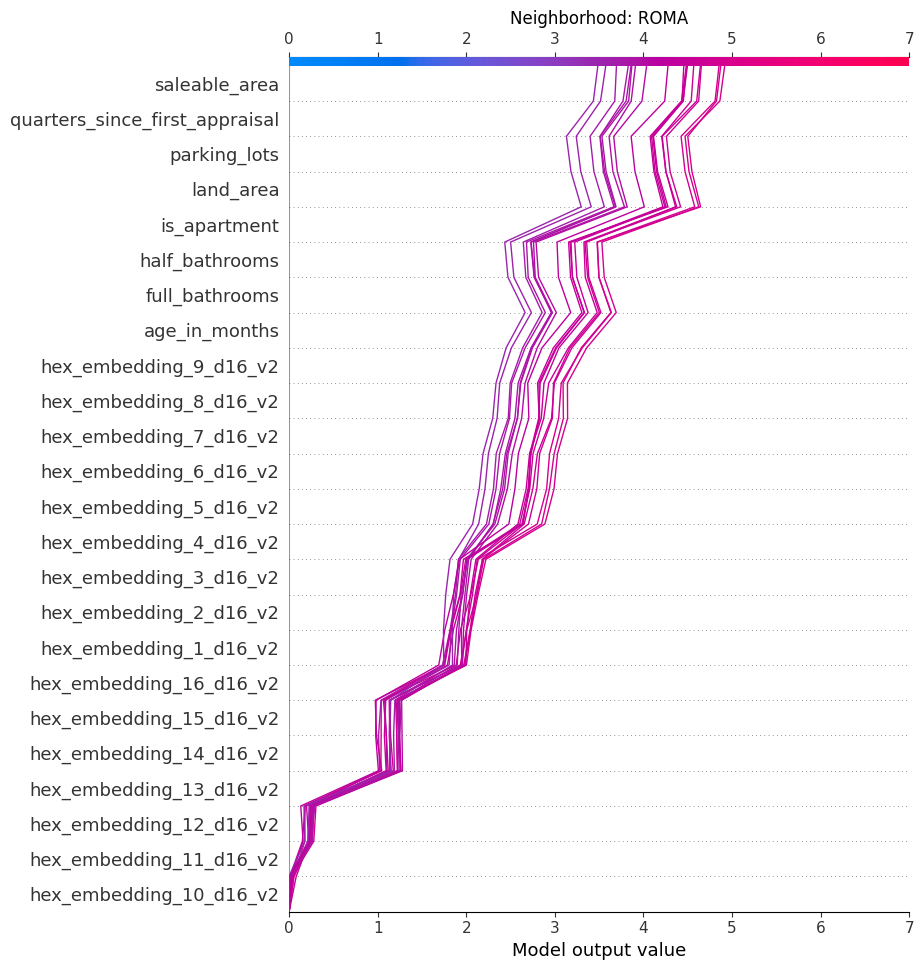

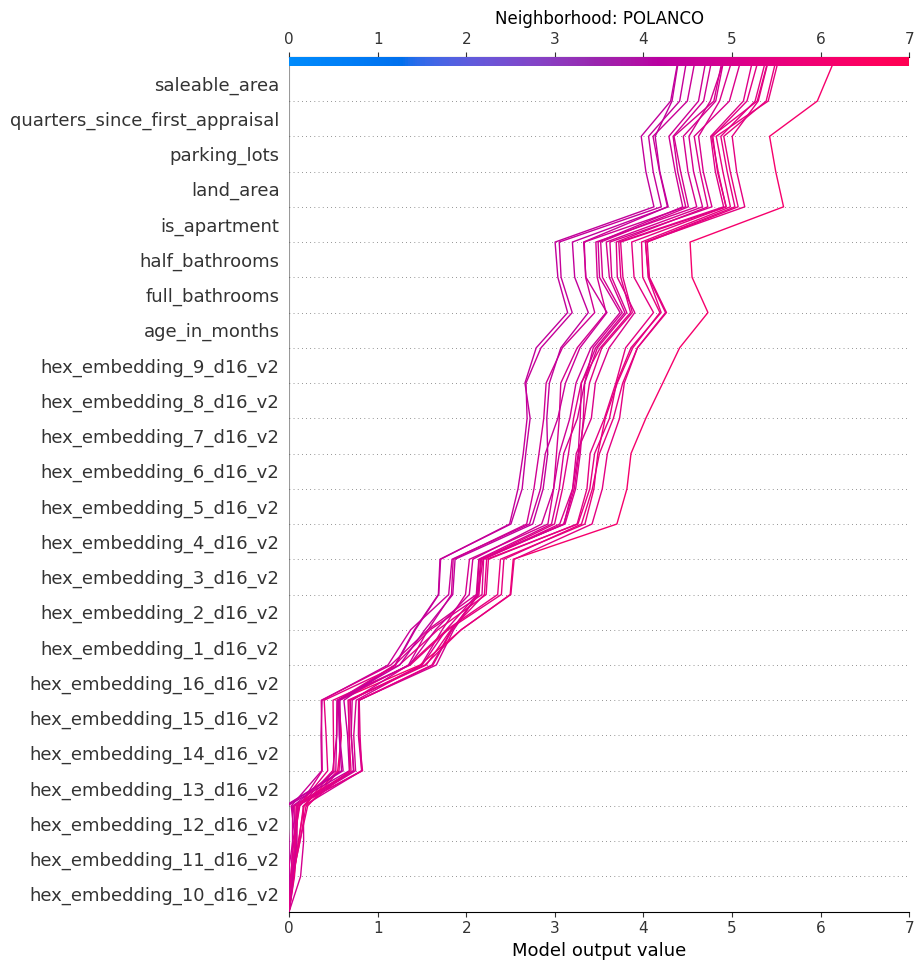

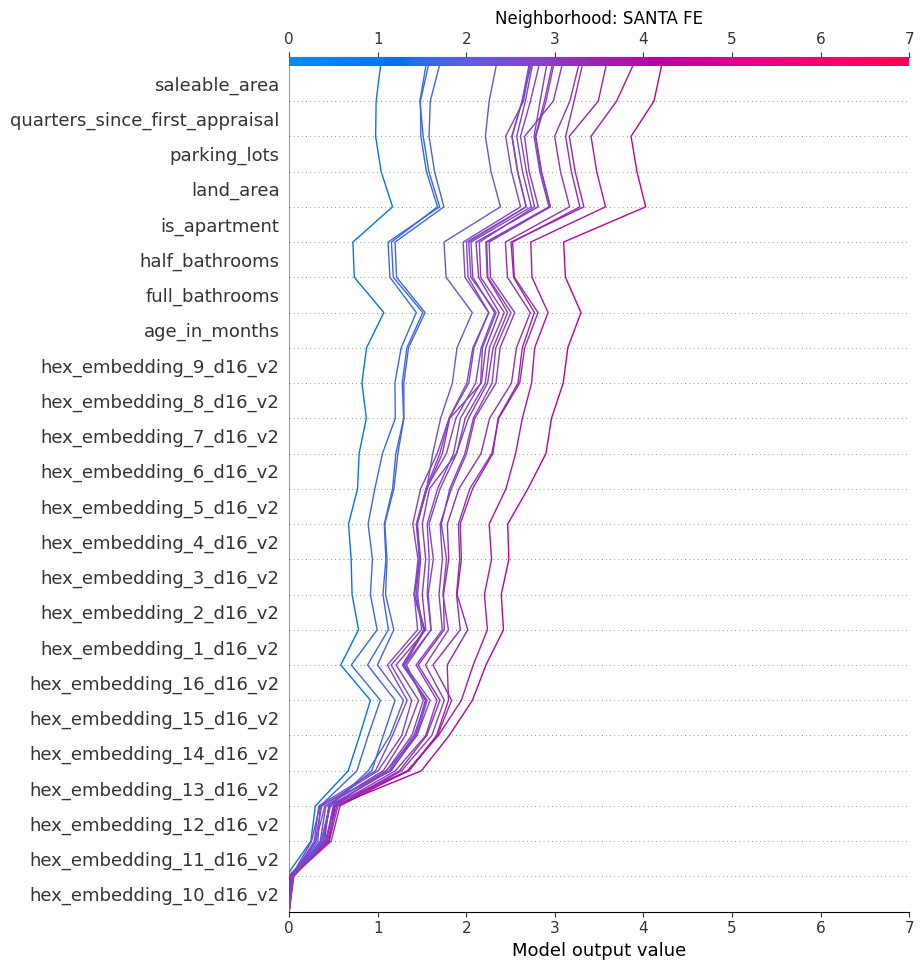

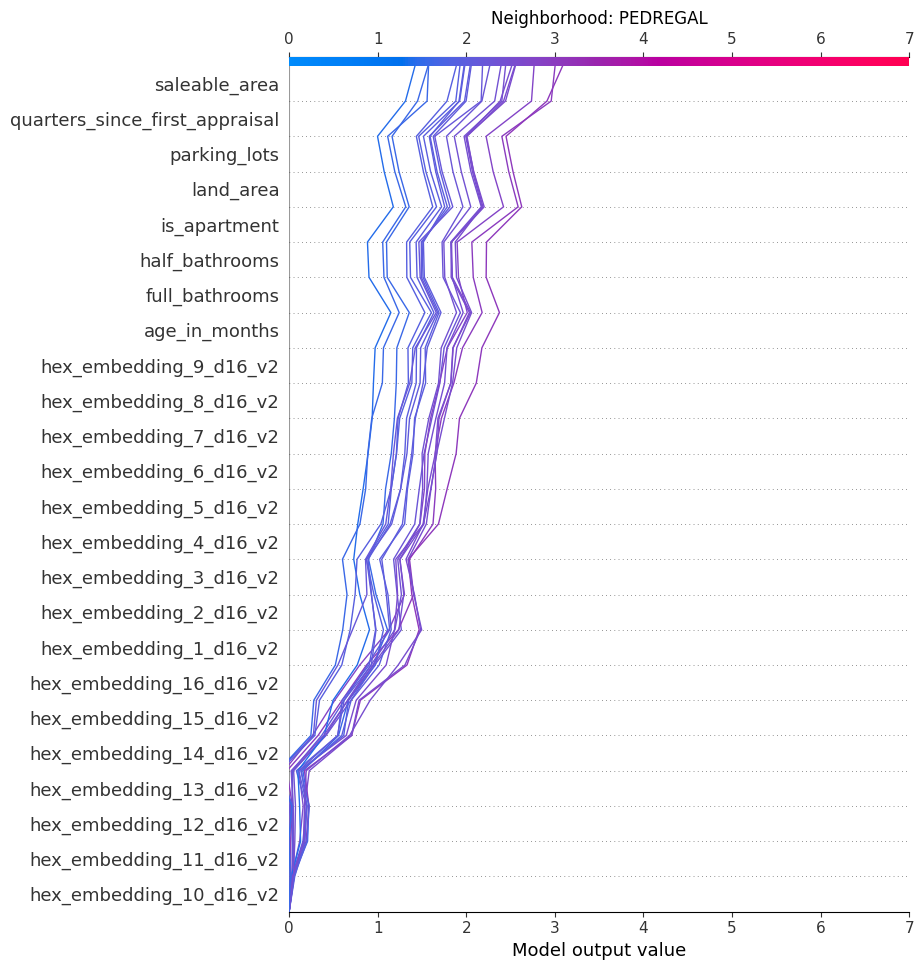

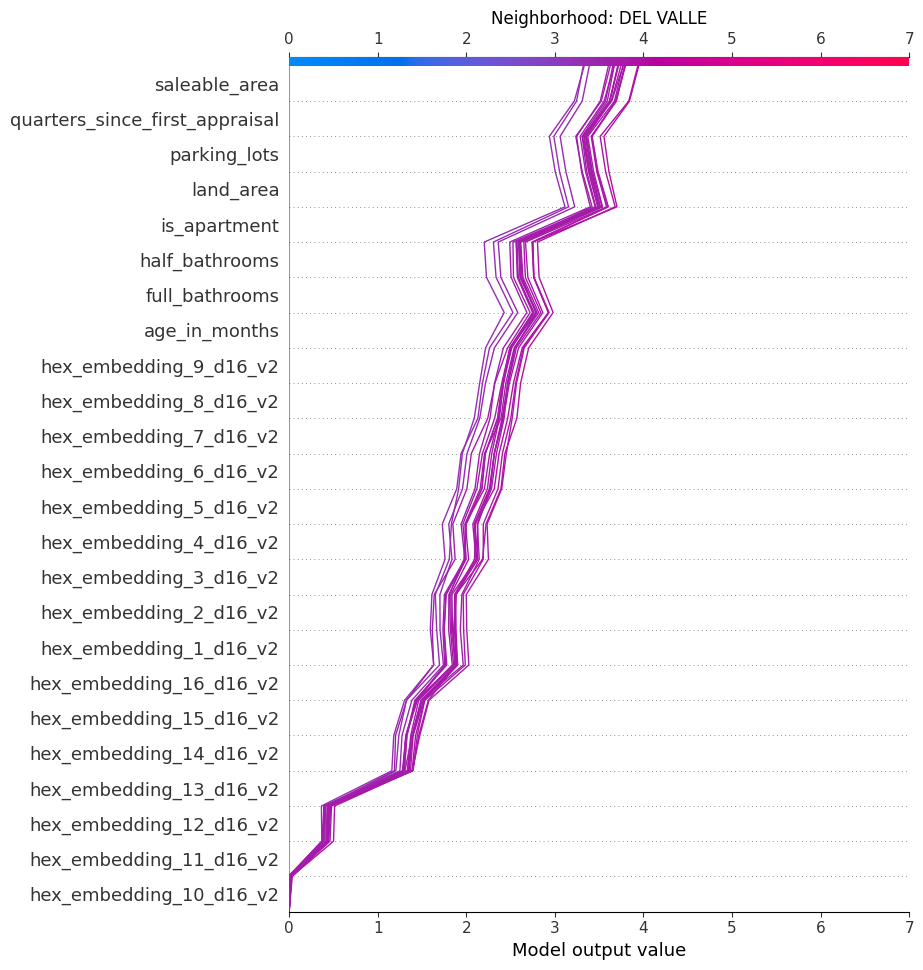

In [164]:
# plot decision plot for each property for each neighborhood
neighborhoods_list = gdf_hex_cdmx_sample.index.unique().to_list()

for neighborhood in neighborhoods_list:
    mask = gdf_hex_cdmx_sample.index == neighborhood
    shap.decision_plot(
        base_value=expected_value,
        shap_values=shap_values_canonical[mask],
        features=gdf_hex_cdmx_sample[mask],
        feature_names=model_feature_names,
        feature_order=feature_order_sorted_indexes,
        feature_display_range=slice(None, None, -1),
        title=f"Neighborhood: {neighborhood}",
        xlim=(0, 7)
    )

### Global Regions

In [165]:
# Get most expensive hex for each city
gdf_hex_price_mexico = (
    df_properties
    # agg log(y) by hex_id
    .groupby(['hex_id', 'city_cluster'], as_index=False)
    .agg(
        avg_log_price=('y', lambda x: np.log(x).mean()),
        count_properties=('y', 'size')
    )
    .reset_index(drop=True)
    .query("count_properties >= 4") # only hex with at least 4 properties
    # get top hex by city_cluster
    .sort_values('avg_log_price', ascending=False, ignore_index=True)
    .groupby('city_cluster', as_index=False)
    .first()
    .reset_index(drop=True)
    .merge(
        gdf_hex_embeddings,
        on='hex_id',
        how='left'
    )
    .assign(
        geometry=lambda x: x['hex_id'].apply(lambda h: Polygon(h3.h3_to_geo_boundary(h, geo_json=True)))
    )
    .set_geometry('geometry')
    .set_crs(epsg=4326)
    .to_crs(epsg=6372)
)


In [166]:
# explore
gdf_hex_price_mexico.explore(
    column='avg_log_price',
    cmap='viridis',
    legend=True,
    tiles='CartoDB positron'
)

In [167]:
# add canonical property
gdf_hex_cdmx_sample = (
    gdf_hex_price_mexico
    .set_index('city_cluster')
    .drop(columns=['hex_id', 'geometry', 'avg_log_price'])
    .assign(**canonical_property)
)

# look
print(gdf_hex_cdmx_sample.shape)
gdf_hex_cdmx_sample.head()

(114, 25)


,count_properties,hex_embedding_1_d16_v2,hex_embedding_2_d16_v2,hex_embedding_3_d16_v2,hex_embedding_4_d16_v2,hex_embedding_5_d16_v2,hex_embedding_6_d16_v2,hex_embedding_7_d16_v2,hex_embedding_8_d16_v2,hex_embedding_9_d16_v2,hex_embedding_10_d16_v2,hex_embedding_11_d16_v2,hex_embedding_12_d16_v2,hex_embedding_13_d16_v2,hex_embedding_14_d16_v2,hex_embedding_15_d16_v2,hex_embedding_16_d16_v2,age_in_months,quarters_since_first_appraisal,is_apartment,half_bathrooms,full_bathrooms,saleable_area,land_area,parking_lots
city_cluster,,,,,,,,,,,,,,,,,,,,,,,,,
0,4,-1.131118,-0.132954,1.210104,-0.618419,2.290266,0.629344,0.053749,-1.087643,-3.054888,-0.577833,-2.871037,1.140678,-1.603771,1.895683,-0.059442,1.737574,1,16,1,0,1,60,60,1
1,56,1.927328,-0.547490,-1.785594,0.608577,1.706026,-1.917169,-0.487000,-0.830589,1.090726,-0.385544,-3.807427,1.839443,-0.648345,1.204168,-0.324050,-1.096769,1,16,1,0,1,60,60,1
2,30,2.812858,-1.716319,1.107841,1.884813,2.112259,-0.802251,-0.615831,0.702282,-1.638616,0.525345,-1.796662,1.686804,-0.046982,1.334933,-1.603298,0.753133,1,16,1,0,1,60,60,1
3,4,1.458746,-0.754034,-2.113397,0.567792,1.343160,-0.872608,0.414561,-1.884590,-1.664714,-2.255863,0.163150,-0.239625,-2.914512,2.812406,0.529519,0.395848,1,16,1,0,1,60,60,1
4,5,-0.736745,-1.441878,0.700594,0.899521,0.804595,0.508516,0.870320,2.449047,-1.322563,-1.411956,-2.087429,2.107231,-2.168440,2.142930,0.284426,1.099724,1,16,1,0,1,60,60,1


In [168]:
# shap values for the canonical property in each hex
shap_values_canonical_global = explainer.shap_values(gdf_hex_cdmx_sample[model_feature_names])
expected_value = explainer.expected_value

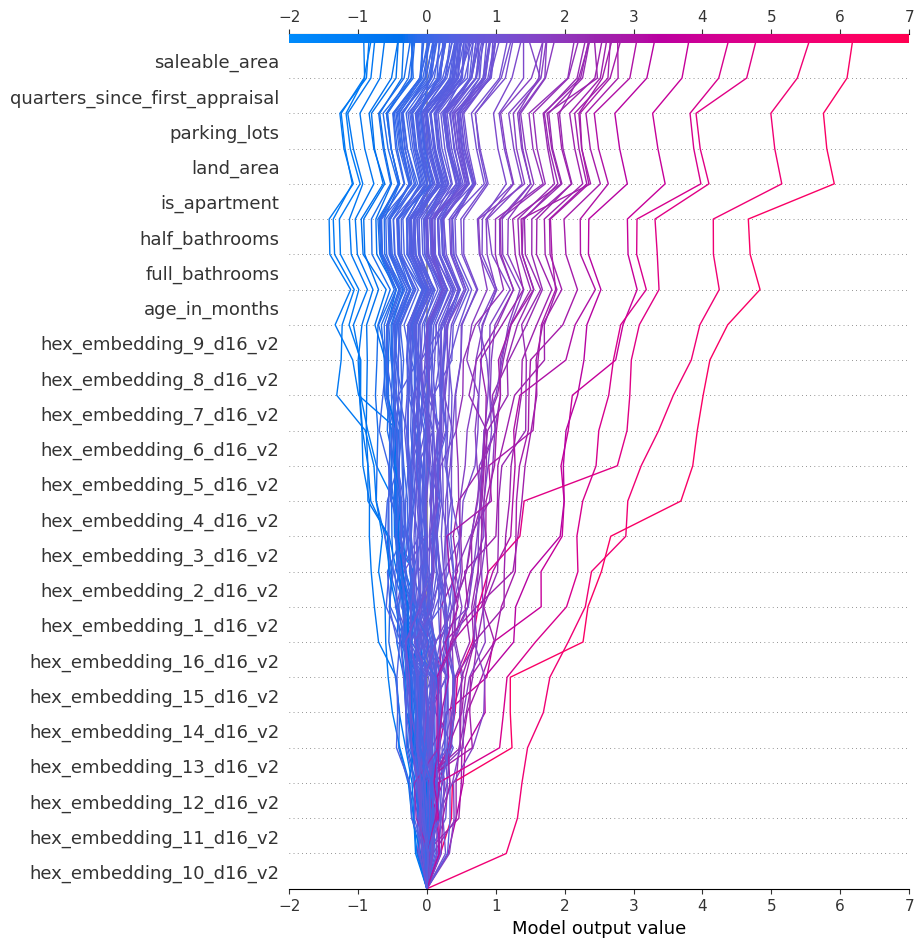

In [169]:
# look shap values for all features
shap.decision_plot(
    base_value=expected_value,
    shap_values=shap_values_canonical_global,
    features=gdf_hex_cdmx_sample,
    feature_names=model_feature_names,
    feature_order=feature_order_sorted_indexes,
    feature_display_range=slice(None, None, -1),
    xlim=(-2, 7)
)

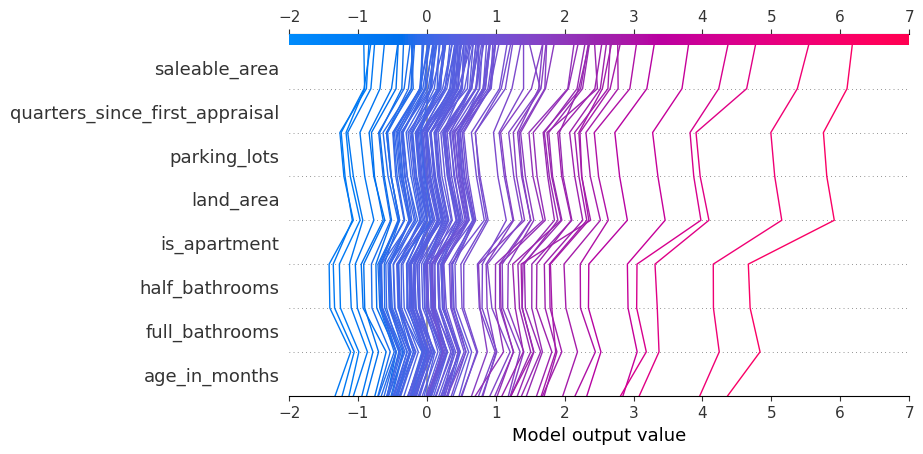

In [170]:
# look shap values for non hex features (zoom in)
shap.decision_plot(
    base_value=expected_value,
    shap_values=shap_values_canonical_global,
    features=gdf_hex_cdmx_sample,
    feature_names=model_feature_names,
    feature_order=feature_order_sorted_indexes,
    feature_display_range=slice(None, -num_non_hex - 1, -1),
    xlim=(-2, 7)
)

### Time Variation

In [171]:
# get hex embeddings from condesa hex 894995ba39bffff
hex_id = '894995ba39bffff'
gdf_hex_condesa = gdf_hex_embeddings.query(f"hex_id == '{hex_id}'")

# add canonical property
gdf_hex_condesa = (
    gdf_hex_condesa
    .drop(columns=['hex_id'])
    .assign(**canonical_property)
)

# variate from 0 to 20 the quarters_since_first_appraisal
gdf_hex_condesa = pd.concat([
    gdf_hex_condesa.assign(quarters_since_first_appraisal=q)
    for q in range(0, 21)
], ignore_index=True)

# look
print(gdf_hex_condesa.shape)
gdf_hex_condesa.head()

(21, 24)


,hex_embedding_1_d16_v2,hex_embedding_2_d16_v2,hex_embedding_3_d16_v2,hex_embedding_4_d16_v2,hex_embedding_5_d16_v2,hex_embedding_6_d16_v2,hex_embedding_7_d16_v2,hex_embedding_8_d16_v2,hex_embedding_9_d16_v2,hex_embedding_10_d16_v2,hex_embedding_11_d16_v2,hex_embedding_12_d16_v2,hex_embedding_13_d16_v2,hex_embedding_14_d16_v2,hex_embedding_15_d16_v2,hex_embedding_16_d16_v2,age_in_months,quarters_since_first_appraisal,is_apartment,half_bathrooms,full_bathrooms,saleable_area,land_area,parking_lots
0,0.43145,-0.712101,-2.195735,-2.417367,1.011254,-0.622554,1.460052,0.720485,-0.66863,-1.823348,-0.107965,0.841126,-3.047433,1.031746,-1.090702,-2.145149,1,0,1,0,1,60,60,1
1,0.43145,-0.712101,-2.195735,-2.417367,1.011254,-0.622554,1.460052,0.720485,-0.66863,-1.823348,-0.107965,0.841126,-3.047433,1.031746,-1.090702,-2.145149,1,1,1,0,1,60,60,1
2,0.43145,-0.712101,-2.195735,-2.417367,1.011254,-0.622554,1.460052,0.720485,-0.66863,-1.823348,-0.107965,0.841126,-3.047433,1.031746,-1.090702,-2.145149,1,2,1,0,1,60,60,1
3,0.43145,-0.712101,-2.195735,-2.417367,1.011254,-0.622554,1.460052,0.720485,-0.66863,-1.823348,-0.107965,0.841126,-3.047433,1.031746,-1.090702,-2.145149,1,3,1,0,1,60,60,1
4,0.43145,-0.712101,-2.195735,-2.417367,1.011254,-0.622554,1.460052,0.720485,-0.66863,-1.823348,-0.107965,0.841126,-3.047433,1.031746,-1.090702,-2.145149,1,4,1,0,1,60,60,1


In [172]:
# shap values for the canonical property in each time
shap_values_condesa_time = explainer.shap_values(gdf_hex_condesa[model_feature_names])
expected_value = explainer.expected_value

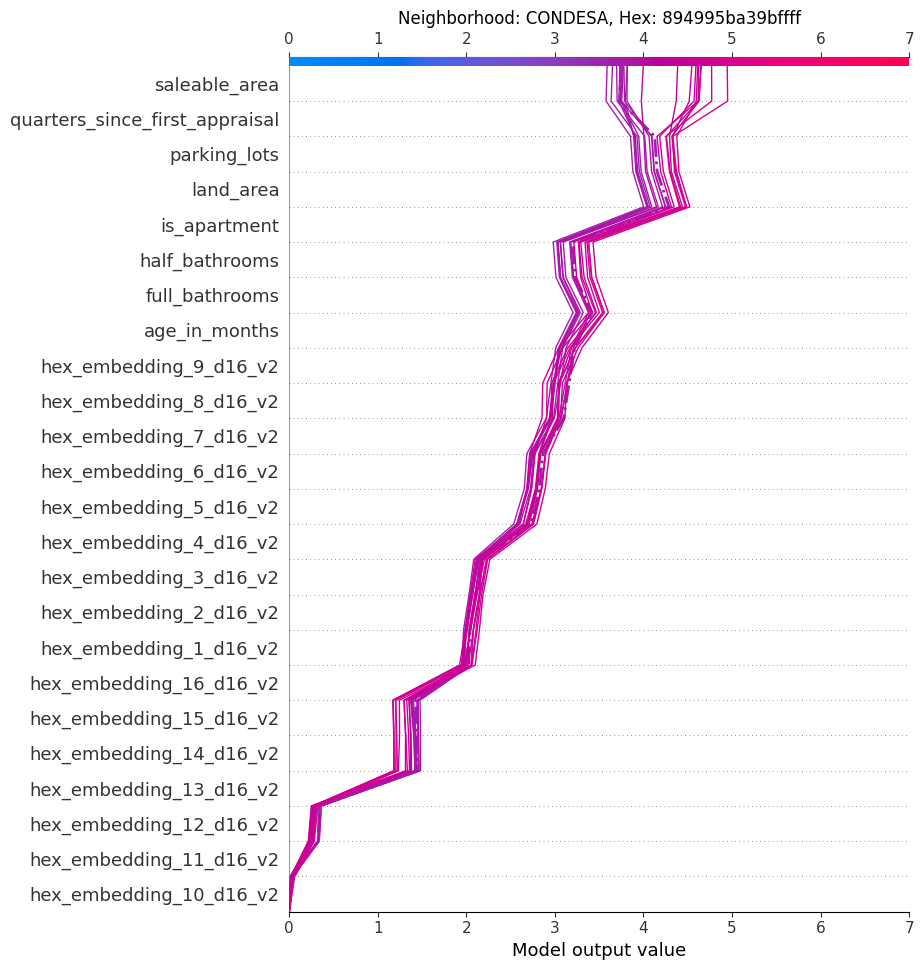

In [173]:
# plot decision plot for each time for condesa property
shap.decision_plot(
    base_value=expected_value,
    shap_values=shap_values_condesa_time,
    features=gdf_hex_condesa,
    feature_names=model_feature_names,
    feature_order=feature_order_sorted_indexes,
    feature_display_range=slice(None, None, -1),
    title=f"Neighborhood: CONDESA, Hex: {hex_id}",
    xlim=(0, 7),
    highlight=0
)

---
# Sandbox

In [28]:
df_properties.query("property_type_id == 4").assign(
    ratio_saleable_land=lambda x: (x['saleable_area'] / x['land_area']).clip(upper=10)
)['ratio_saleable_land'].lt(1).mean()

0.2847301050166699

<Axes: ylabel='Frequency'>

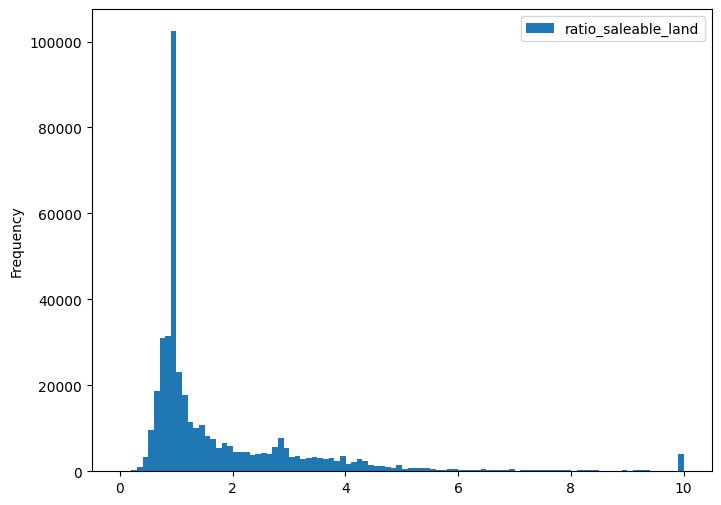

In [27]:
df_properties.query("property_type_id == 4").assign(
    ratio_saleable_land=lambda x: (x['saleable_area'] / x['land_area']).clip(upper=10)
).plot(
    kind='hist',
    y='ratio_saleable_land',
    bins=100,
    figsize=(8, 6)
)

In [32]:
df_properties.query("property_type_id == 4 and land_area > saleable_area")

,y,y_pred,y_fitted,y_pred_fitted,set,half_bathrooms,full_bathrooms,property_class_more_common_in_area,neighborhood,constructor,zip_code,age_in_months,parking_lots,valuation_date,potable_water_service_id,lighting_service_id,sidewalk_id,project_quality_id,property_class_id,conservation_status_id,controller_id,elevator_service_id,state_id,equipment_id,curb_id,infrastructure_service_id,road_materials_id,municipality_id,grantor_id,urban_proximity_id,water_collection_service_id,electrical_supply_service_id,telephone_service_supply_id,property_type_id,public_transportation_service_id,valuation_unit_id,valuation_professional_id,level,total_levels,purpose_of_appraisal,bedrooms,built_area,saleable_area,land_area,rentable_units,rentable_units_subject_property,current_use,market_price,price,built_price,land_price,access_routes,remaining_useful_life,property_id,city_cluster,ppsm_comps,ppsm_lower_comps,ppsm_upper_comps,num_neighbors,distance_to_ocean,ocean_label,accessory_area,hex_id,count_supermarkets_at_1km,count_hospitals_at_5km,count_metro_at_1km,count_schools_at_1km,count_restaurants_at_1km,tam_loc,est_socio,clase_hog,sexo_jefe,edad_jefe,educa_jefe,tot_integ,mayores,menores,p12_64,p65mas,percep_ing,ing_cor,estim_alqu,otros_ing,gasto_mon,vivienda,alquiler,pred_cons,cuidados,tipo_viv,antiguedad,cuart_dorm,tenencia,renta,estim_pago,pago_viv,pago_mesp,tipo_adqui,viv_usada,tipo_finan,escrituras,tot_resid,tot_hom,tot_muj,tot_hog,total_viviendas,lag_year_inpc,lag_3months_em_avg_pct_change_inpc,lag_year_general_minimum_wage,lag_3months_em_avg_general_wage,ppsm_terrain,ppsm_terrain_lower,ppsm_terrain_upper,hex_longitude,hex_latitude,hex_embedding_1_d16_v2,hex_embedding_2_d16_v2,hex_embedding_3_d16_v2,hex_embedding_4_d16_v2,hex_embedding_5_d16_v2,hex_embedding_6_d16_v2,hex_embedding_7_d16_v2,hex_embedding_8_d16_v2,hex_embedding_9_d16_v2,hex_embedding_10_d16_v2,hex_embedding_11_d16_v2,hex_embedding_12_d16_v2,hex_embedding_13_d16_v2,hex_embedding_14_d16_v2,hex_embedding_15_d16_v2,hex_embedding_16_d16_v2,longitude,latitude
observation_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
148dd882-8cec-434d-ab33-a762faa426c2,10525.000000,10582.937500,-0.502343,-0.489939,train,0,1,3,REGION 065,NO APLICA,77723,0,0,2019-04-12,1,3,1,1,3,6,34e46c5f-11c3-4c22-afc4-ead80d8e108b,2,23,3,1,3,2,008,98013144-6a9f-4e08-9255-cb54568d2f5a,3,1,2,2,4,1,bfe2dd96-5fa8-43e8-b679-533e42090d64,6a9c3931-ae31-4d41-8403-a0098c9e9d38,4,2,S/D,2,40,40,50,4,1,TERRENO DONDE SE DESPLANTA EL CONJUNTO HABITAC...,421072,421000,242460,95950,EL ACCESO AL DESARROLLO ES POR LA CARRETERA CA...,60,24128a64-abb5-5265-8f52-778f41b603f8,8,10457,10308,10609,60,10000,mar_caribe,0.00,89450a1808bffff,0,0,0,0,0,1.000000,2.125000,2,1,38.12500,6.585938,3.261719,2.603516,0.659180,2.560547,0.042419,2.132812,56480.390625,4058.396729,65.036064,41352.601562,7123.578613,5199.178711,75.620903,1589.596558,1.0,6.351562,1.490234,1,1766.300659,1384.307861,337.991119,0.716116,1.0,0.049561,1,1,3.265625,1.757812,1.508789,1.004883,72896,99.1250,0.004471,103.8750,0.049988,2546,1038,4975,20.678519,-87.132648,-0.200028,-1.361624,-1.072907,0.740351,1.365730,-2.597566,-0.017984,-0.959619,-2.840051,-1.403227,1.158682,0.741836,-3.145484,0.717600,-2.009741,0.159004,-87.131744,20.679223
5bf6c03a-a24c-44f1-be09-c79279f3531b,27305.555556,26468.636719,1.651579,1.581246,train,0,2,4,COLINAS DEL LAGO CONJ RANCHO DE FUENTES SITTIA,ICH 002 SAPI DE CV,54744,0,1,2020-11-19,0,0,0,0,4,6,1f637d21-f0cb-43be-b989-5923e4c01d94,2,15,4,0,4,2,121,2c2cf133-a887-495e-b0b1-c48c0d83173f,2,0,0,0,4,0,90a0a9f7-fab3-4170-b3da-db49e122e41b,108d9918-c800-47f5-865a-b227d7361b0d,3,1,S/D,2,72,72,91,0,0,<NA>,1851000,1966000,726360,468026,<NA>,70,9aa2d523-7e40-5cfc-a362-63522582ef3c,10,26027,24436,27806,60,100000,no_ocean,0.00,894995af4c3ffff,2,1,0,0,0,1.000000,3.191406,2,1,52.03125,7.156250,3.572266,3.101562,0.470703,2.919922,0.183228,1.967773,97548.640625,10937.011719,0.000

<Axes: xlabel='land_area', ylabel='saleable_area'>

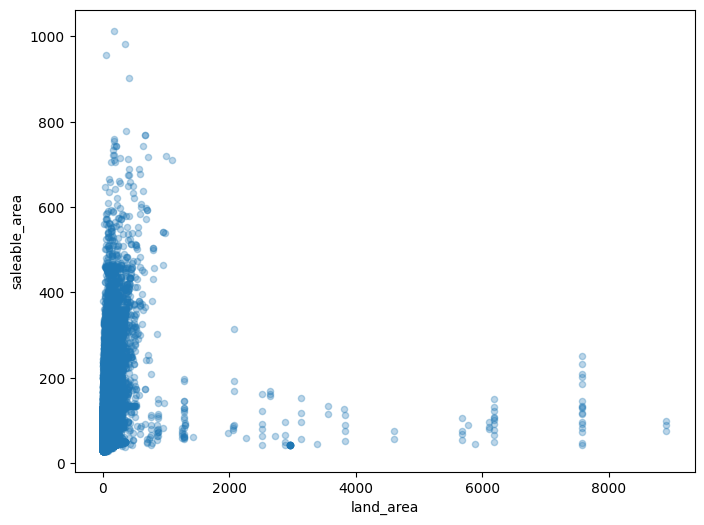

In [25]:
df_properties.query("property_type_id == 4")[['saleable_area', 'land_area']].plot(
    kind='scatter',
    x='land_area',
    y='saleable_area',
    alpha=0.3,
    figsize=(8, 6)
)

In [19]:
non_hex_columns

['half_bathrooms',
 'full_bathrooms',
 'age_in_months',
 'saleable_area',
 'land_area',
 'is_apartment',
 'parking_lots',
 'quarters_since_first_appraisal']

In [ ]:
shap_values

In [ ]:
shap_values_non_hex.feature_names

In [ ]:
type(shap_values)